# 🦠 Hackathon – Dataset C: Who will accept a COVID vaccine?
### Minimising the total money a town spends on COVID vaccines + COVID hospitalisations

**Module:** 7PAM2002 – University of Hertfordshire
**GitHub organisation:** `https://github.com/Group-Q-Hackathon-Research-Methods` | **Colab:** `<add link>`
**Team members:** `<add names>`

---

**What this notebook does (one line):** we predict, for every resident in the test town, whether they will accept a COVID vaccine,
and we turn those predictions into *send / don't send* decisions that **minimise the expected total cost** (vaccines + hospitalisations) –
not accuracy or F1.

| Section | Content |
|---|---|
| 1 | Set-up (works locally **and** in Google Colab) |
| 2 | Understanding the task and **deriving the task-specific cost metric** (with research on hospitalisation risk) |
| 3 | Exploratory Data Analysis (EDA) – data quality, missingness, distributions, associations, train/test shift |
| 4 | Pre-processing – cleaning, feature engineering, and a **comparison of four pre-processing options** |
| 5 | Modelling – six model families + an ensemble, **hyper-parameter tuning**, repeated cross-validation |
| 6 | Turning probabilities into decisions – three decision strategies, threshold analysis, calibration |
| 7 | Performance on unseen hold-out data, bootstrap uncertainty, **robustness to the hospitalisation assumptions** |
| 8 | Final model selection, re-training on all data and **writing the five ranked submission files** |
| 9 | Explainable AI – SHAP, odds ratios, permutation importance (incl. *cost-based* importance) |
| 10 | Conclusions, limitations and a non-technical summary |

## 1. Set-up
The first cell installs anything missing (CatBoost is not pre-installed on Colab). Everything is seeded so results are reproducible.

In [6]:
# ---- Install missing libraries (only does something if a package is missing, e.g. CatBoost on Colab) ----
import sys, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules

def ensure(package, pip_name=None):
    # Import a package, installing it with pip first if it is not available.
    try:
        importlib.import_module(package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name or package])

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:
    ensure(pkg)
print('Running in Colab:', IN_COLAB)

Running in Colab: False


In [7]:
# ---- Imports ----
import os, time, warnings
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, f1_score, accuracy_score
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool
import shap

warnings.filterwarnings('ignore', message='X does not have valid feature names')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

SK_VERSION = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
print('scikit-learn', sklearn.__version__)

scikit-learn 1.6.1


In [3]:
# ---- Global configuration ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path('data')            # folder holding the three csv files
FIG_DIR = Path('figures')          # every figure is also saved here for the presentation
SUB_DIR = Path('submissions')      # the five ranked prediction files
for d in (FIG_DIR, SUB_DIR):
    d.mkdir(exist_ok=True)

N_JOBS = -1                        # use all CPU cores

# Colour palette (colour-blind-checked categorical order) and a consistent plot style
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = PALETTE
GREY, INK, INK2 = '#8c8b86', '#0b0b0b', '#52514e'
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#f2f6fc', '#9cc2ef', '#2a78d6', '#103a6e'])
DIV_CMAP = LinearSegmentedColormap.from_list('div', [ORANGE, '#f2f1ee', BLUE])

mpl.rcParams.update({
    'axes.prop_cycle': mpl.cycler(color=PALETTE),
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'font.size': 10,
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

def savefig(name):
    # Save the current figure (PNG) so it can be reused in the slides.
    plt.savefig(FIG_DIR / f'{name}.png')

In [8]:
# ---- Load the data ----
# Locally / from GitHub: put the csv files in ./data
# In Colab: if ./data is empty you will be asked to upload the 3 csv files.
FILES = {'train': 'dataset_C_training.csv', 'test': 'dataset_C_testing.csv',
         'sample': 'dataset_C_example_submission.csv'}

if IN_COLAB and not (DATA_DIR / FILES['train']).exists():
    from google.colab import files
    DATA_DIR.mkdir(exist_ok=True)
    print('Please upload: dataset_C_training.csv, dataset_C_testing.csv, dataset_C_example_submission.csv')
    for name, content in files.upload().items():
        clean_name = next((f for f in FILES.values() if f in name), name)   # handle "file (1).csv"
        (DATA_DIR / clean_name).write_bytes(content)

train_raw = pd.read_csv(DATA_DIR / FILES['train'])
test_raw = pd.read_csv(DATA_DIR / FILES['test'])
sample_sub = pd.read_csv(DATA_DIR / FILES['sample'])

TARGET, ID = 'covid_vaccine', 'respondent_id'
FEATURES = [c for c in train_raw.columns if c not in (ID, TARGET)]
print('train:', train_raw.shape, '| test:', test_raw.shape, '| sample submission:', sample_sub.shape)
train_raw.head()

train: (4756, 31) | test: (4749, 30) | sample submission: (4749, 2)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,child_under_6_months,health_worker,health_insurance,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,NaN,45 - 54 Years,12 Years,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,45 - 54 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Not Married,Own,Employed,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,NaN,65+ Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,18 - 34 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


In [9]:
# ---- Feature groups (from the dataset information sheet) ----
BEHAVIOURAL = [c for c in FEATURES if c.startswith('behavioral_')]
OPINION = ['opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc']
BINARY = BEHAVIOURAL + ['doctor_recc_covid', 'child_under_6_months', 'health_worker', 'health_insurance']
ORDINAL_NUM = ['covid_concern', 'covid_knowledge'] + OPINION + ['household_adults', 'household_children',
                                                               'number_chronic_med_conditions']
CATEGORICAL = ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own',
               'employment_status', 'census_msa', 'employment_sector']
assert set(BINARY + ORDINAL_NUM + CATEGORICAL) == set(FEATURES), 'every feature must be in exactly one group'

AGE_ORDER = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
EDU_ORDER = ['< 12 Years', '12 Years', 'Some College', 'College Graduate']
INC_ORDER = ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000']
print(f'{len(BINARY)} binary, {len(ORDINAL_NUM)} ordinal/count, {len(CATEGORICAL)} categorical features')

11 binary, 8 ordinal/count, 10 categorical features


## 2. Understanding the task and deriving the evaluation metric

### 2.1 What exactly are we being scored on?
The brief says the goal is to **minimise the total money spent by the town**, made of (i) vaccine costs and (ii) hospitalisation costs.
The rules translate into a cost for every combination of *our decision* and *the person's true behaviour*:

* Everybody gets infected (100 % infection probability at winter parties).
* A vaccine is **posted to the person's home** if we predict they will accept it (ŷ = 1). If they refuse, the dose is ruined but has still been paid for.
* If we do **not** send a vaccine but the person wanted one (false negative), **the town must pay them the vaccine cost in cash** – and they stay unvaccinated.
* Hospitalisation cost = probability of hospitalisation × \$41 000. That probability depends on the person's characteristics and on whether they are vaccinated.

| Our decision ↓ / truth → | **Accepts** (y = 1) | **Refuses** (y = 0) |
|---|---|---|
| **Send vaccine** (ŷ = 1) | \$1 500 + 41 000·p·(1 − VE)  ← *vaccinated* | \$1 500 (wasted) + 41 000·p |
| **Don't send** (ŷ = 0) | \$1 500 (cash) + 41 000·p | \$0 + 41 000·p |

where **p** = probability that this *unvaccinated* person is hospitalised once infected, and **VE** = vaccine effectiveness against hospitalisation.

### 2.2 Consequences (why accuracy / F1 are the wrong targets)
* A false positive and a false negative cost the *same* \$1 500 directly, **but** only a true positive saves hospitalisation money
  (41 000 · p · VE). So the value of correctly reaching a willing person depends on *who* they are: an 18–34 year old with no
  chronic disease is "worth" a few hundred dollars of avoided hospital costs, a 65+ year old with chronic conditions is worth many thousands.
* Taking expectations with q = P(person accepts | features), sending is better than not sending when

$$\underbrace{1500 + q\,[41000\,p(1-VE)] + (1-q)\,41000\,p}_{\text{send}} \;<\; \underbrace{q\,1500 + 41000\,p}_{\text{don't send}}
\;\;\Longleftrightarrow\;\; q \;>\; t_i = \frac{1500}{1500 + 41000\cdot p_i\cdot VE}$$

So the **cost-optimal decision threshold is personal**: it is low (≈0.2) for high-risk residents and high (≈0.7) for low-risk residents.
A single threshold of 0.5 is never optimal. This is why we need (a) **well-calibrated probabilities** q and (b) a **hospitalisation-risk model** p.

### 2.3 Estimating the hospitalisation probability p (research)
The brief asks us to use generative AI to estimate p and to check robustness. We used an AI assistant grounded in published sources:

| Quantity | Value used | Source / reasoning |
|---|---|---|
| Infection-hospitalisation ratio by age (unvaccinated, pre-Omicron) | 18–49: 2.7 %, 50–64: 7.3 %, 65+: 17.9 % | CDC *Estimated COVID-19 Burden* Feb 2020–Sep 2021: hospitalisations ÷ infections per age group (e.g. 65+: 3.23 M / 18.0 M) |
| Split into the dataset's age bands | 18–34: 1.9 %, 35–44: 3.2 %, 45–54: 4.9 %, 55–64: 8.2 %, 65+: 17.9 % | log-linear interpolation that reproduces the CDC band averages |
| Chronic conditions (count) | relative risk 1 → 2.0, 2 → 3.0, 3+ → 4.0 | CDC/COVID-NET: ≥1 condition aRR 2.2–4.6; Atlanta cohort: >3 conditions aOR 4.2; French national cohort: 5+ HR ≈ 5.9 |
| Sex | male RR 1.33 | meta-analysis of 229 studies: men had RR 1.33 for hospitalisation once infected |
| Vaccine effectiveness against hospitalisation | 85 % | meta-analyses report ≈ 89 % (two doses); we shade down slightly for waning / variants |

Multipliers are **normalised within each age group** so that the town's average risk per age group still equals the CDC figure
(otherwise we would double-count the fact that older people have more chronic conditions).

**Robustness ("ask different AIs").** Different assistants / people give different numbers, so every result is also evaluated under four alternative
scenarios: age-only risk, one flat average risk for the whole town, a milder Omicron-era scenario (half the risk, VE 70 %), and a severe scenario
(1.5× risk, VE 95 %). The team can add the answers they obtained from Gemini/ChatGPT to `EXTRA_AI_SCENARIOS` below and every table updates automatically.

In [10]:
# ---- Costs given in the dataset information sheet ----
VACCINE_COST = 1_500     # $ per dose (also the cash paid to a willing person who did not get a dose)
HOSP_COST = 41_000       # $ per hospitalisation


@dataclass
class HospScenario:
    # A set of assumptions about P(hospitalisation | infected, unvaccinated) and vaccine effectiveness.
    name: str
    age_ihr: dict                 # infection-hospitalisation ratio per age group
    cond_rr: dict = None          # relative risk by number of chronic conditions (None = ignore)
    male_rr: float = 1.0          # relative risk for men
    ve: float = 0.85              # vaccine effectiveness against hospitalisation
    scale: float = 1.0            # multiply all risks (e.g. milder variant)
    flat: bool = False            # True = give everybody the town-average risk

    def _multiplier(self, df):
        mult = np.ones(len(df))
        if self.cond_rr:
            n = df['number_chronic_med_conditions'].clip(upper=max(self.cond_rr))
            mult *= n.map(self.cond_rr).to_numpy()
        mult *= np.where(df['sex'].eq('Male'), self.male_rr, 1.0)
        return mult

    def fit(self, town):
        # Normalise the multipliers so that each age group's mean risk equals the published IHR for that age.
        self.norm_ = pd.Series(self._multiplier(town)).groupby(town['age_group'].to_numpy()).mean().to_dict()
        self.town_mean_ = self._individual(town).mean()
        return self

    def _individual(self, df):
        base = df['age_group'].map(self.age_ihr).to_numpy(dtype=float) * self.scale
        norm = df['age_group'].map(self.norm_).to_numpy(dtype=float)
        return np.clip(base * self._multiplier(df) / norm, 0, 0.95)

    def p_unvacc(self, df):
        # P(hospitalised | infected, NOT vaccinated) for every row of df.
        return np.full(len(df), self.town_mean_) if self.flat else self._individual(df)

    def personal_threshold(self, df):
        # Accept-probability above which sending a vaccine lowers the expected cost (see derivation).
        return VACCINE_COST / (VACCINE_COST + HOSP_COST * self.ve * self.p_unvacc(df))

    def global_threshold(self):
        # Optimal single threshold if everybody had the town-average risk.
        return VACCINE_COST / (VACCINE_COST + HOSP_COST * self.ve * self.town_mean_)

    def cost(self, y, send, df):
        # Total town cost (in $) of the decisions `send` for people with true behaviour `y`.
        y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
        p = self.p_unvacc(df)
        vaccine_money = VACCINE_COST * (send | y)                 # dose sent (used or wasted) or cash paid
        hosp_money = HOSP_COST * p * np.where(send & y, 1 - self.ve, 1.0)
        return float(vaccine_money.sum() + hosp_money.sum())

    def breakdown(self, y, send, df):
        y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
        p = self.p_unvacc(df)
        exp_hosp = (p * np.where(send & y, 1 - self.ve, 1.0)).sum()
        return {'doses used (TP)': int((send & y).sum()), 'doses wasted (FP)': int((send & ~y).sum()),
                'cash payouts (FN)': int((~send & y).sum()), 'expected hospitalisations': round(exp_hosp, 1),
                'vaccine-related $': VACCINE_COST * int((send | y).sum()), 'hospital $': round(HOSP_COST * exp_hosp),
                'TOTAL $': round(self.cost(y, send, df))}


AGE_IHR = {'18 - 34 Years': 0.019, '35 - 44 Years': 0.032, '45 - 54 Years': 0.049,
           '55 - 64 Years': 0.082, '65+ Years': 0.179}
COND_RR = {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}

# The whole town we have information about (train + test) is used to normalise the risk multipliers
TOWN = pd.concat([train_raw[FEATURES], test_raw[FEATURES]], ignore_index=True)

MAIN = HospScenario('A: age+conditions+sex (main)', AGE_IHR, COND_RR, male_rr=1.33, ve=0.85).fit(TOWN)
SCENARIOS = [
    MAIN,
    HospScenario('B: age only', AGE_IHR, None, ve=0.85).fit(TOWN),
    HospScenario('C: flat town average', AGE_IHR, COND_RR, male_rr=1.33, ve=0.85, flat=True).fit(TOWN),
    HospScenario('D: mild (Omicron-like)', AGE_IHR, COND_RR, male_rr=1.33, ve=0.70, scale=0.5).fit(TOWN),
    HospScenario('E: severe, high VE', AGE_IHR, COND_RR, male_rr=1.33, ve=0.95, scale=1.5).fit(TOWN),
]
# ---- Add answers from other AIs here, e.g. ----
# EXTRA_AI_SCENARIOS = [HospScenario('F: Gemini answer', {'18 - 34 Years': 0.01, ...}, ve=0.9).fit(TOWN)]
EXTRA_AI_SCENARIOS = []
SCENARIOS += EXTRA_AI_SCENARIOS

print(f'Average unvaccinated hospitalisation risk in the town: {MAIN.town_mean_:.2%}')
print(f'Optimal single threshold (flat risk):                  {MAIN.global_threshold():.3f}')
pd.DataFrame({s.name: {'mean p': round(s.town_mean_, 4), 've': s.ve, 'global threshold': round(s.global_threshold(), 3)}
              for s in SCENARIOS}).T

Average unvaccinated hospitalisation risk in the town: 8.20%
Optimal single threshold (flat risk):                  0.344


,mean p,ve,global threshold
A: age+conditions+sex (main),0.082,0.85,0.344
B: age only,0.082,0.85,0.344
C: flat town average,0.082,0.85,0.344
D: mild (Omicron-like),0.041,0.70,0.560
"E: severe, high VE",0.123,0.95,0.239


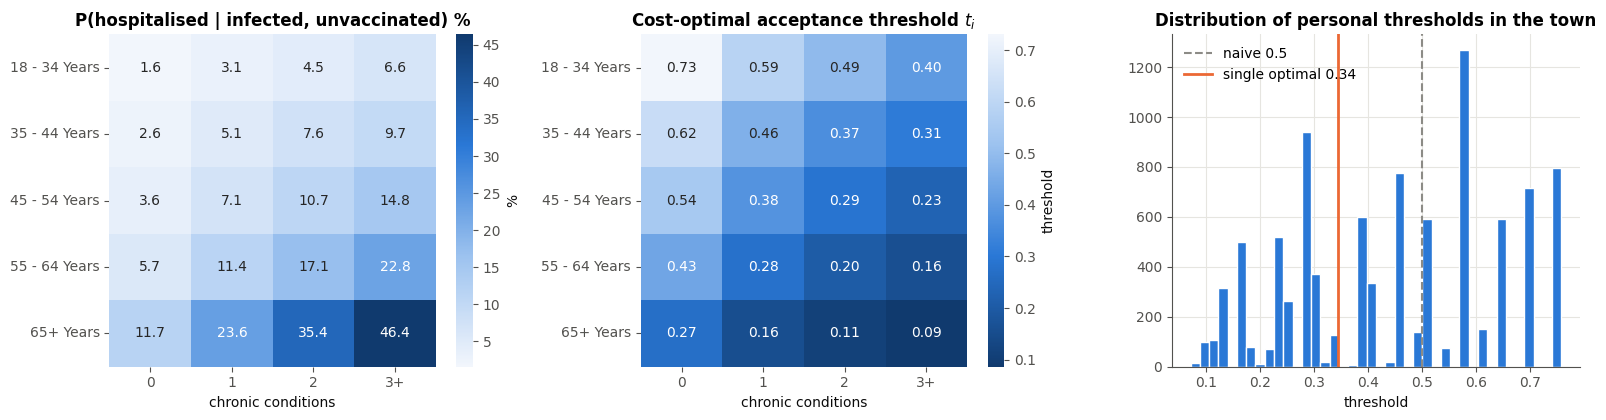

In [11]:
# ---- How does the risk model look across the town? ----
town_view = TOWN.assign(p_hosp=MAIN.p_unvacc(TOWN), threshold=MAIN.personal_threshold(TOWN),
                        chronic=TOWN['number_chronic_med_conditions'].clip(upper=3).astype(str).replace('3', '3+'))
risk_table = town_view.pivot_table(index='age_group', columns='chronic', values='p_hosp', aggfunc='mean').reindex(AGE_ORDER)
thr_table = town_view.pivot_table(index='age_group', columns='chronic', values='threshold', aggfunc='mean').reindex(AGE_ORDER)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.heatmap(risk_table * 100, annot=True, fmt='.1f', cmap=SEQ_CMAP, ax=axes[0], cbar_kws={'label': '%'})
axes[0].set_title('P(hospitalised | infected, unvaccinated) %'); axes[0].set_xlabel('chronic conditions'); axes[0].set_ylabel('')
sns.heatmap(thr_table, annot=True, fmt='.2f', cmap=SEQ_CMAP.reversed(), ax=axes[1], cbar_kws={'label': 'threshold'})
axes[1].set_title('Cost-optimal acceptance threshold $t_i$'); axes[1].set_xlabel('chronic conditions'); axes[1].set_ylabel('')
axes[2].hist(town_view['threshold'], bins=40, color=BLUE, edgecolor='white')
axes[2].axvline(0.5, color=GREY, ls='--', lw=1.5, label='naive 0.5')
axes[2].axvline(MAIN.global_threshold(), color=ORANGE, lw=2, label=f'single optimal {MAIN.global_threshold():.2f}')
axes[2].set_title('Distribution of personal thresholds in the town'); axes[2].set_xlabel('threshold'); axes[2].legend()
plt.tight_layout(); savefig('02_risk_model'); plt.show()

**Reading the figure.** Under the main scenario the town's average unvaccinated hospitalisation risk is roughly 8 %, giving a
single optimal threshold around 0.35 (lower than 0.5 because a missed willing person is expensive). The personal thresholds
spread from ≈0.75 (young, healthy women) down to ≈0.1 (65+ with several chronic conditions). This metric will be our
**main evaluation measure**, reported as **$ per resident** (so that folds and data sets of different sizes are comparable) and as the
**total for the test town** (4 749 residents).

In [12]:
# ---- Reference points on the training data: what do trivial strategies cost? ----
def cost_per_person(y, send, df, scenario=MAIN):
    return scenario.cost(y, send, df) / len(y)

y_all = train_raw[TARGET].to_numpy()
refs = {
    'Send to nobody (pay cash to all willing)': np.zeros_like(y_all),
    'Send to everybody': np.ones_like(y_all),
    'Send only if doctor recommended': train_raw['doctor_recc_covid'].to_numpy(),
    'Perfect knowledge (oracle)': y_all,
}
pd.DataFrame({k: {s.name: round(cost_per_person(y_all, v, train_raw, s), 1) for s in SCENARIOS}
              for k, v in refs.items()}).T.rename_axis('$ per resident (training data)')

,A: age+conditions+sex (main),B: age only,C: flat town average,D: mild (Omicron-like),"E: severe, high VE"
$ per resident (training data),,,,,
Send to nobody (pay cash to all willing),3809.3,3793.3,3850.8,2149.7,5469.0
Send to everybody,3743.5,3793.9,3927.3,2716.6,4675.3
Send only if doctor recommended,3333.9,3395.4,3499.6,2014.4,4602.3
Perfect knowledge (oracle),2733.6,2784.0,2917.5,1706.8,3665.5


The gap between *send to nobody* and the *oracle* is the money a perfect model could save. Note that **"send to everybody"
is already better than "send to nobody"** under the main scenario – vaccinating willing elderly people is very valuable – so a useful model must beat
*both* trivial strategies. All later results are compared with these reference points.

## 3. Exploratory Data Analysis
### 3.1 Overview, types and basic statistics

In [13]:
overview = pd.DataFrame({
    'dtype': train_raw[FEATURES].dtypes.astype(str),
    'n_unique': train_raw[FEATURES].nunique(),
    'missing_train_%': (train_raw[FEATURES].isna().mean() * 100).round(1),
    'missing_test_%': (test_raw[FEATURES].isna().mean() * 100).round(1),
    'example_values': [list(train_raw[c].dropna().unique()[:4]) for c in FEATURES],
})
overview['group'] = ['binary' if c in BINARY else 'ordinal/count' if c in ORDINAL_NUM else 'categorical' for c in FEATURES]
print('Duplicated respondent ids:', train_raw[ID].duplicated().sum(),
      '| duplicated feature rows:', train_raw[FEATURES].duplicated().sum(),
      '| id overlap train/test:', len(set(train_raw[ID]) & set(test_raw[ID])))
overview.sort_values('missing_train_%', ascending=False)

Duplicated respondent ids: 0 | duplicated feature rows: 0 | id overlap train/test: 0


,dtype,n_unique,missing_train_%,missing_test_%,example_values,group
employment_sector,object,21,49.0,50.6,"[construction, education, wholesale, science]",categorical
health_insurance,float64,2,40.1,41.7,"[1.0, 0.0]",binary
income_poverty,object,3,15.7,16.8,"[<= $75,000, Above Poverty, > $75,000, Below P...",categorical
rent_or_own,object,2,6.9,8.0,"[Own, Rent]",categorical
employment_status,object,3,5.0,5.8,"[Employed, Not in Labor Force, Unemployed]",categorical
marital_status,object,2,4.9,5.7,"[Married, Not Married]",categorical
education,object,4,4.8,5.7,"[12 Years, College Graduate, Some College, < 1...",categorical
child_under_6_months,float64,2,2.8,3.3,"[0.0, 1.0]",binary
health_worker,float64,2,2.8,3.1,"[0.0, 1.0]",binary
opinion_covid_sick_from_vacc,float64,5,1.9,2.3,"[2.0, 1.0, 5.0, 4.0]",ordinal/count


In [14]:
train_raw[BINARY + ORDINAL_NUM + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
behavioral_antiviral_meds,4742.0,0.05,0.22,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,0.73,0.44,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,0.07,0.26,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,0.84,0.37,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,0.69,0.46,0.0,0.0,1.0,1.0,1.0
doctor_recc_covid,4756.0,0.23,0.42,0.0,0.0,0.0,0.0,1.0
child_under_6_months,4621.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
health_worker,4624.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0


### 3.2 The target

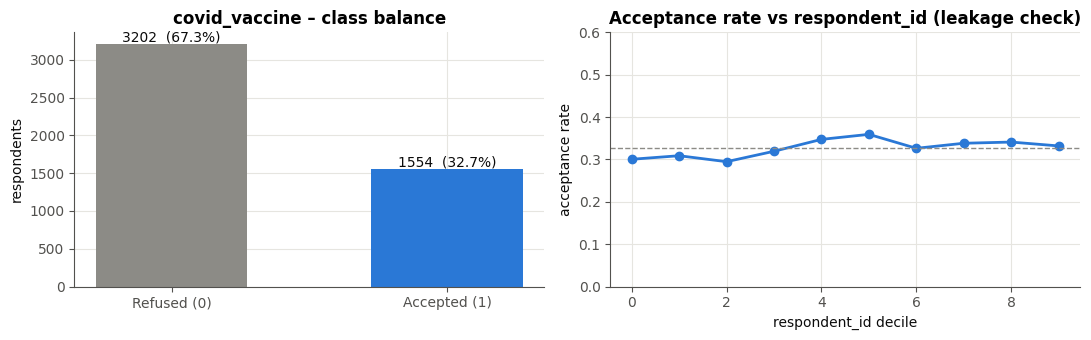

AUC of respondent_id alone: 0.515


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
counts = train_raw[TARGET].value_counts().sort_index()
axes[0].bar(['Refused (0)', 'Accepted (1)'], counts.values, color=[GREY, BLUE], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 40, f'{v}  ({v / counts.sum():.1%})', ha='center', color=INK)
axes[0].set_title('covid_vaccine – class balance'); axes[0].set_ylabel('respondents')

# Is the (random) respondent id predictive?  It should not be – check for ordering/leakage.
binned = pd.qcut(train_raw[ID], 10, labels=False)
axes[1].plot(train_raw.groupby(binned)[TARGET].mean().values, marker='o', color=BLUE, lw=2)
axes[1].axhline(train_raw[TARGET].mean(), color=GREY, ls='--', lw=1)
axes[1].set_ylim(0, 0.6); axes[1].set_xlabel('respondent_id decile'); axes[1].set_ylabel('acceptance rate')
axes[1].set_title('Acceptance rate vs respondent_id (leakage check)')
plt.tight_layout(); savefig('03_target'); plt.show()
print('AUC of respondent_id alone:', round(roc_auc_score(train_raw[TARGET], train_raw[ID]), 3))

* **≈33 % accept** the vaccine – a moderate imbalance. We will **not** re-balance (SMOTE / class weights) because that would distort the
  predicted probabilities, and our decision rule needs *calibrated* probabilities. The cost-based threshold handles the imbalance instead.
* `respondent_id` carries no signal (AUC ≈ 0.5, flat deciles), so it is dropped as a feature.

### 3.3 Missing values – how much, where, and are they informative?

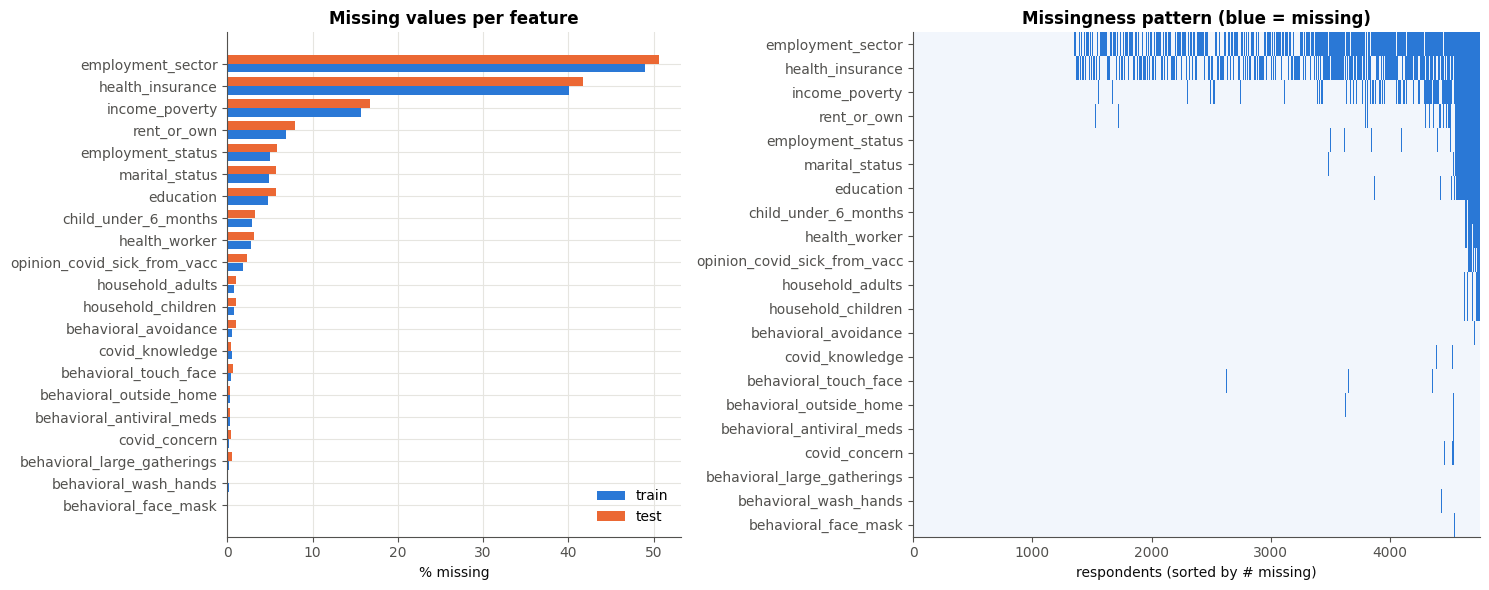

In [16]:
miss = pd.DataFrame({'train': train_raw[FEATURES].isna().mean(), 'test': test_raw[FEATURES].isna().mean()}) * 100
miss = miss[miss.max(axis=1) > 0].sort_values('train')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.25]})
y_pos = np.arange(len(miss))
axes[0].barh(y_pos - 0.2, miss['train'], height=0.38, color=BLUE, label='train')
axes[0].barh(y_pos + 0.2, miss['test'], height=0.38, color=ORANGE, label='test')
axes[0].set_yticks(y_pos, miss.index); axes[0].set_xlabel('% missing'); axes[0].legend(loc='lower right')
axes[0].set_title('Missing values per feature')

# Missingness matrix: rows sorted by number of missing values -> shows that missingness is clustered
order = train_raw[FEATURES].isna().sum(axis=1).sort_values().index
mat = train_raw.loc[order, miss.index[::-1]].isna().to_numpy().T
axes[1].imshow(mat, aspect='auto', cmap=LinearSegmentedColormap.from_list('m', ['#f2f6fc', BLUE]), interpolation='nearest')
axes[1].set_yticks(range(len(miss)), miss.index[::-1]); axes[1].set_xlabel('respondents (sorted by # missing)')
axes[1].set_title('Missingness pattern (blue = missing)'); axes[1].grid(False)
plt.tight_layout(); savefig('03_missing'); plt.show()

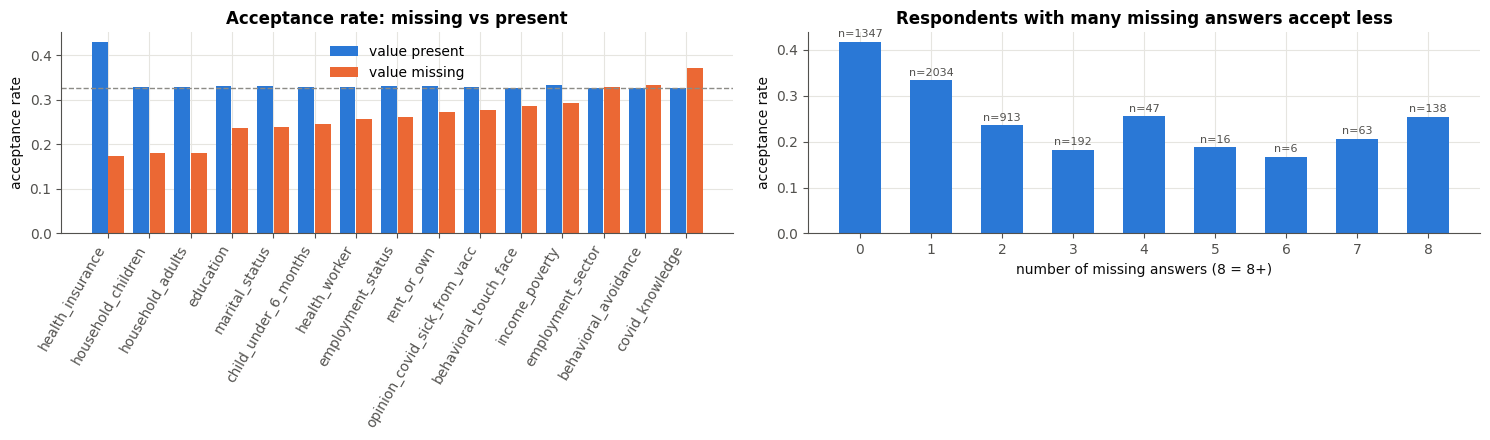

,feature,n_missing,rate_if_missing,rate_if_present
13,health_insurance,1908,0.173,0.430
3,household_children,39,0.179,0.328
4,household_adults,39,0.179,0.328
8,education,228,0.237,0.331
9,marital_status,231,0.238,0.331
7,child_under_6_months,135,0.244,0.329
6,health_worker,132,0.258,0.329
10,employment_status,238,0.261,0.330
11,rent_or_own,329,0.274,0.331
5,opinion_covid_sick_from_vacc,90,0.278,0.328


In [17]:
# Is "being missing" related to the target?  Compare acceptance rate when the value is missing vs present.
rows = []
for c in miss.index:
    is_na = train_raw[c].isna()
    if is_na.sum() >= 20:
        rows.append({'feature': c, 'n_missing': int(is_na.sum()),
                     'rate_if_missing': train_raw.loc[is_na, TARGET].mean(),
                     'rate_if_present': train_raw.loc[~is_na, TARGET].mean()})
mt = pd.DataFrame(rows).sort_values('rate_if_missing')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(mt))
axes[0].bar(x - 0.2, mt['rate_if_present'], 0.38, color=BLUE, label='value present')
axes[0].bar(x + 0.2, mt['rate_if_missing'], 0.38, color=ORANGE, label='value missing')
axes[0].set_xticks(x, mt['feature'], rotation=60, ha='right'); axes[0].set_ylabel('acceptance rate')
axes[0].axhline(train_raw[TARGET].mean(), color=GREY, ls='--', lw=1); axes[0].legend()
axes[0].set_title('Acceptance rate: missing vs present')

n_miss = train_raw[FEATURES].isna().sum(axis=1).clip(upper=8)
g = train_raw.groupby(n_miss)[TARGET].agg(['mean', 'size'])
axes[1].bar(g.index.astype(str), g['mean'], color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    axes[1].text(i, m + 0.01, f'n={n}', ha='center', fontsize=8, color=INK2)
axes[1].set_xlabel('number of missing answers (8 = 8+)'); axes[1].set_ylabel('acceptance rate')
axes[1].set_title('Respondents with many missing answers accept less')
plt.tight_layout(); savefig('03_missing_vs_target'); plt.show()
mt.round(3)

**Findings on missingness**
* `employment_sector` (≈49 %) and `health_insurance` (≈40 %) are heavily missing; most other features < 10 %.
* Missingness is **not random**: people who skip `health_insurance`, `income_poverty`, `health_worker`… accept the vaccine *less often*
  (e.g. ~17 % vs ~43 % for health insurance). Respondents with many skipped answers are less engaged and less likely to accept.
* ⇒ Dropping rows or blindly mean-imputing would throw away signal. We will test **"missing" as its own category + missing-indicator flags**.

### 3.4 Data-quality problems hidden in the values

In [18]:
# 1) Opinion scales are documented as 1-5, yet some rows contain 0
for c in OPINION:
    vc = train_raw[c].value_counts(dropna=False).sort_index()
    print(f'{c:32s}', dict(vc))
zero_rows = train_raw[OPINION[:2]].eq(0).any(axis=1)
print('\nMean # of missing answers | opinion == 0:', round(train_raw.loc[zero_rows, FEATURES].isna().sum(axis=1).mean(), 2),
      ' vs others:', round(train_raw.loc[~zero_rows, FEATURES].isna().sum(axis=1).mean(), 2))

# 2) employment_sector is missing *by design* for people who are not employed
print('\nemployment_sector missing, by employment_status:')
print(pd.crosstab(train_raw['employment_status'].fillna('(missing)'), train_raw['employment_sector'].isna(),
                  colnames=['sector missing']))

# 3) doctor_recc_covid has no missing values at all, unlike every other survey answer (missing probably coded as 0)
print('\ndoctor_recc_covid missing values:', train_raw['doctor_recc_covid'].isna().sum())

opinion_covid_vacc_effective     {0: np.int64(92), 1: np.int64(124), 2: np.int64(241), 3: np.int64(772), 4: np.int64(2425), 5: np.int64(1102)}
opinion_covid_risk               {0: np.int64(96), 1: np.int64(1196), 2: np.int64(1228), 3: np.int64(982), 4: np.int64(1029), 5: np.int64(225)}
opinion_covid_sick_from_vacc     {1.0: np.int64(2115), 2.0: np.int64(1358), 3.0: np.int64(10), 4.0: np.int64(876), 5.0: np.int64(307), nan: np.int64(90)}

Mean # of missing answers | opinion == 0: 8.38  vs others: 1.22

employment_sector missing, by employment_status:
sector missing      False  True 
employment_status               
(missing)               0    238
Employed             2426     25
Not in Labor Force      0   1808
Unemployed              0    259

doctor_recc_covid missing values: 0


**Data-quality decisions**
1. `opinion_covid_vacc_effective` and `opinion_covid_risk` contain **0**, which is not a valid answer (scale 1–5). Rows with a 0 have
   ~7× more missing answers than others, so **0 is a disguised missing value → recode to NaN**.
2. `employment_sector` is missing for 2 300 people **because they are not employed** – that is not "unknown", it is a real category
   → fill with `not_employed` (only the 25 employed people + people with unknown status are truly missing).
3. `opinion_covid_sick_from_vacc = 3` ("don't know") is almost never used (10 rows) – harmless, kept as ordinal.
4. `number_chronic_med_conditions` has a long tail (only 12 people with ≥4) → **top-code at 3** (a simple binning step).

### 3.5 Does the test set look like the training set? (distribution shift)

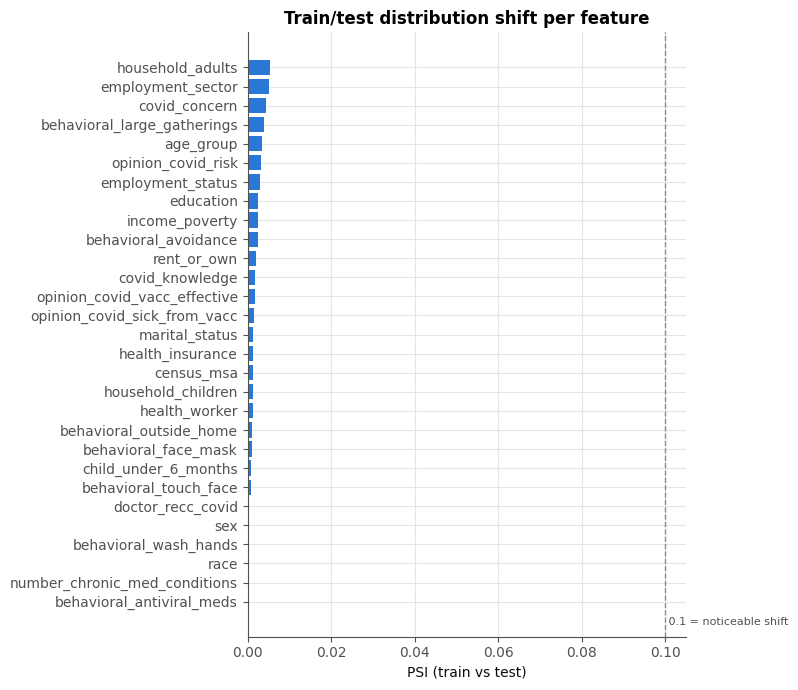

Largest PSI: household_adults 0.0053


In [19]:
def psi(a, b, eps=1e-4):
    # Population Stability Index between two samples of a discrete variable (NaN treated as a category).
    a, b = a.fillna('NaN').astype(str), b.fillna('NaN').astype(str)
    cats = sorted(set(a) | set(b))
    pa = a.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
    pb = b.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
    return float(((pa - pb) * np.log(pa / pb)).sum())

shift = pd.Series({c: psi(train_raw[c], test_raw[c]) for c in FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(shift.index, shift.values, color=[ORANGE if v > 0.1 else BLUE for v in shift.values])
ax.axvline(0.1, color=GREY, ls='--', lw=1); ax.text(0.1, -1.2, ' 0.1 = noticeable shift', color=INK2, fontsize=8)
ax.set_xlabel('PSI (train vs test)'); ax.set_title('Train/test distribution shift per feature')
plt.tight_layout(); savefig('03_shift'); plt.show()
print('Largest PSI:', shift.idxmax(), round(shift.max(), 4))

All PSI values are far below 0.1 → the test town has the **same population profile** as the training sample, so cross-validated
estimates should transfer well to the test set.

### 3.6 Univariate distributions

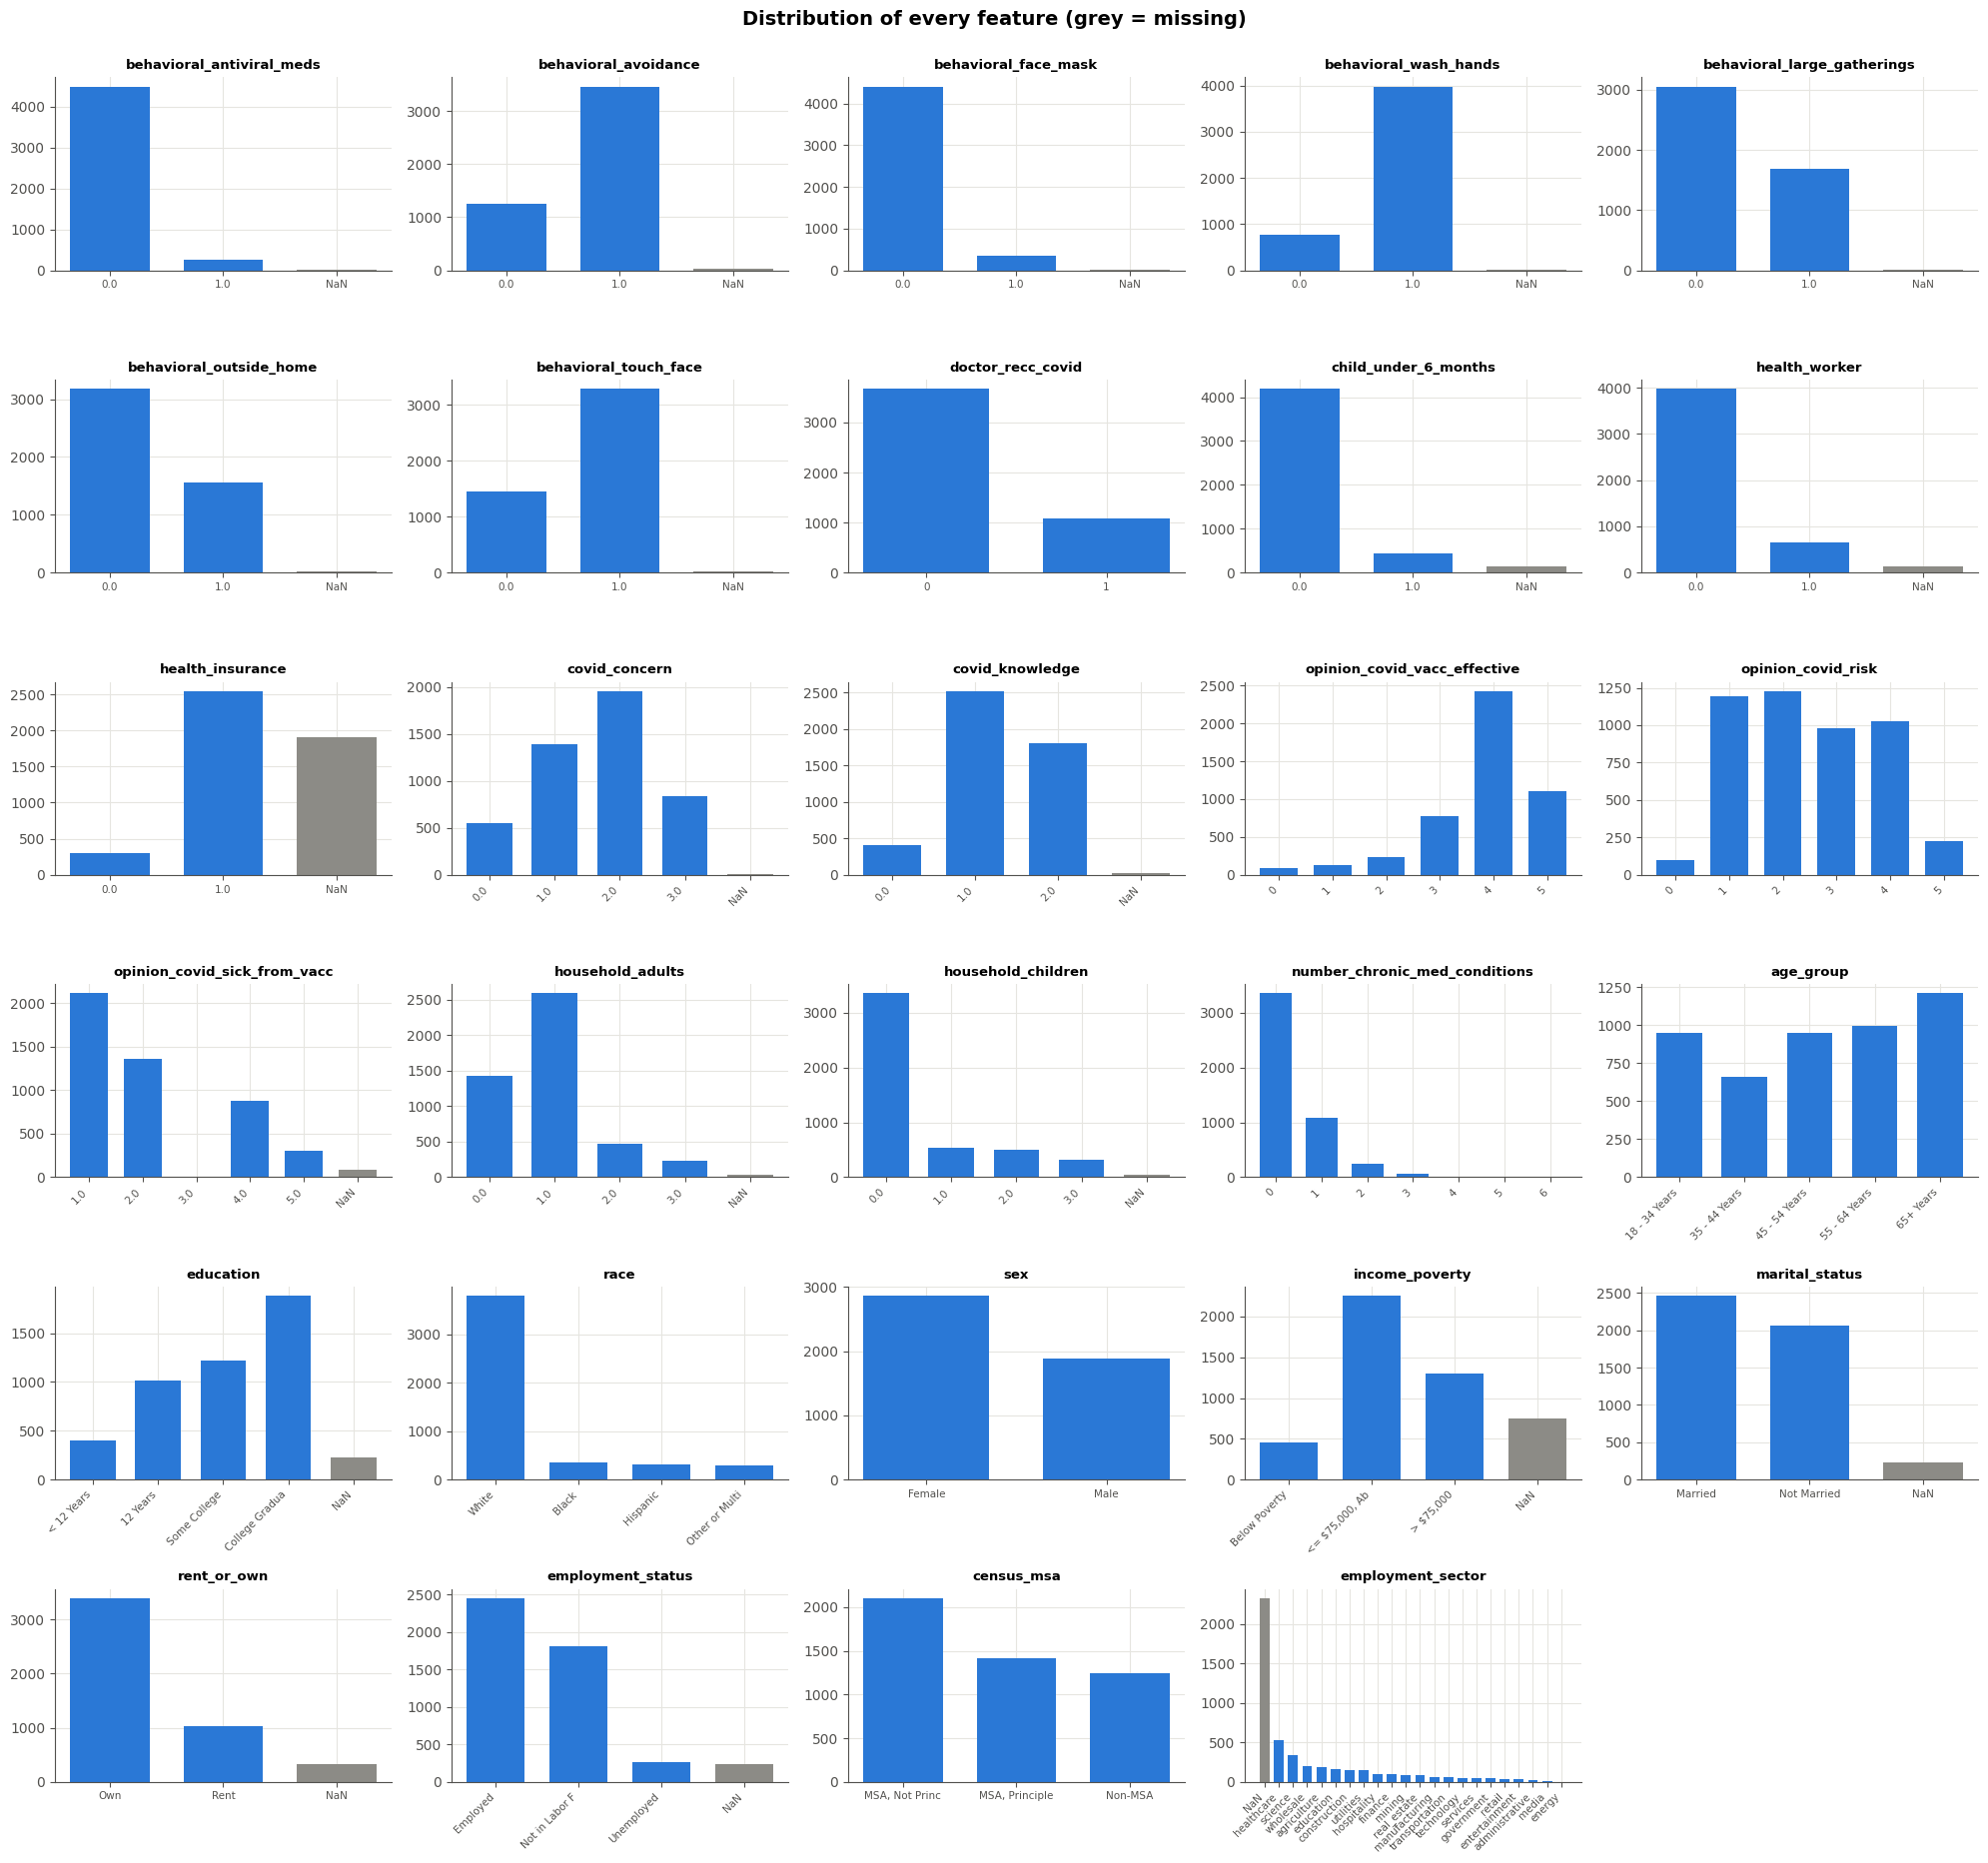

In [20]:
plot_cols = BINARY + ORDINAL_NUM + CATEGORICAL
n_cols = 5
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.1 * n_rows))
for ax, c in zip(axes.flat, plot_cols):
    vc = train_raw[c].fillna('NaN').astype(str).value_counts()
    if c in ['age_group', 'education', 'income_poverty']:
        order = {'age_group': AGE_ORDER, 'education': EDU_ORDER, 'income_poverty': INC_ORDER}[c]
        vc = vc.reindex([o for o in order + ['NaN'] if o in vc.index])
    elif c not in CATEGORICAL:
        vc = vc.sort_index()
    labels = [str(l)[:14] for l in vc.index]
    ax.bar(labels, vc.values, color=[GREY if l == 'NaN' else BLUE for l in vc.index], width=0.7)
    ax.set_title(c, fontsize=9.5); ax.tick_params(axis='x', labelrotation=45 if len(vc) > 3 else 0, labelsize=7.5)
    for lab in ax.get_xticklabels():
        lab.set_horizontalalignment('right' if len(vc) > 3 else 'center')
for ax in list(axes.flat)[len(plot_cols):]:
    ax.axis('off')
plt.suptitle('Distribution of every feature (grey = missing)', y=1.0, fontsize=14, fontweight='bold')
plt.tight_layout(); savefig('03_univariate'); plt.show()

Observations: most behavioural questions are heavily skewed (e.g. 80 %+ wash hands, < 5 % took antivirals); the sample is older than the
general population (25 % aged 65+); ~80 % White; `employment_sector` has many rare categories (several with < 30 people) → rare
categories will be grouped (`min_frequency` in one-hot encoding).

### 3.7 How does each feature relate to vaccine acceptance?

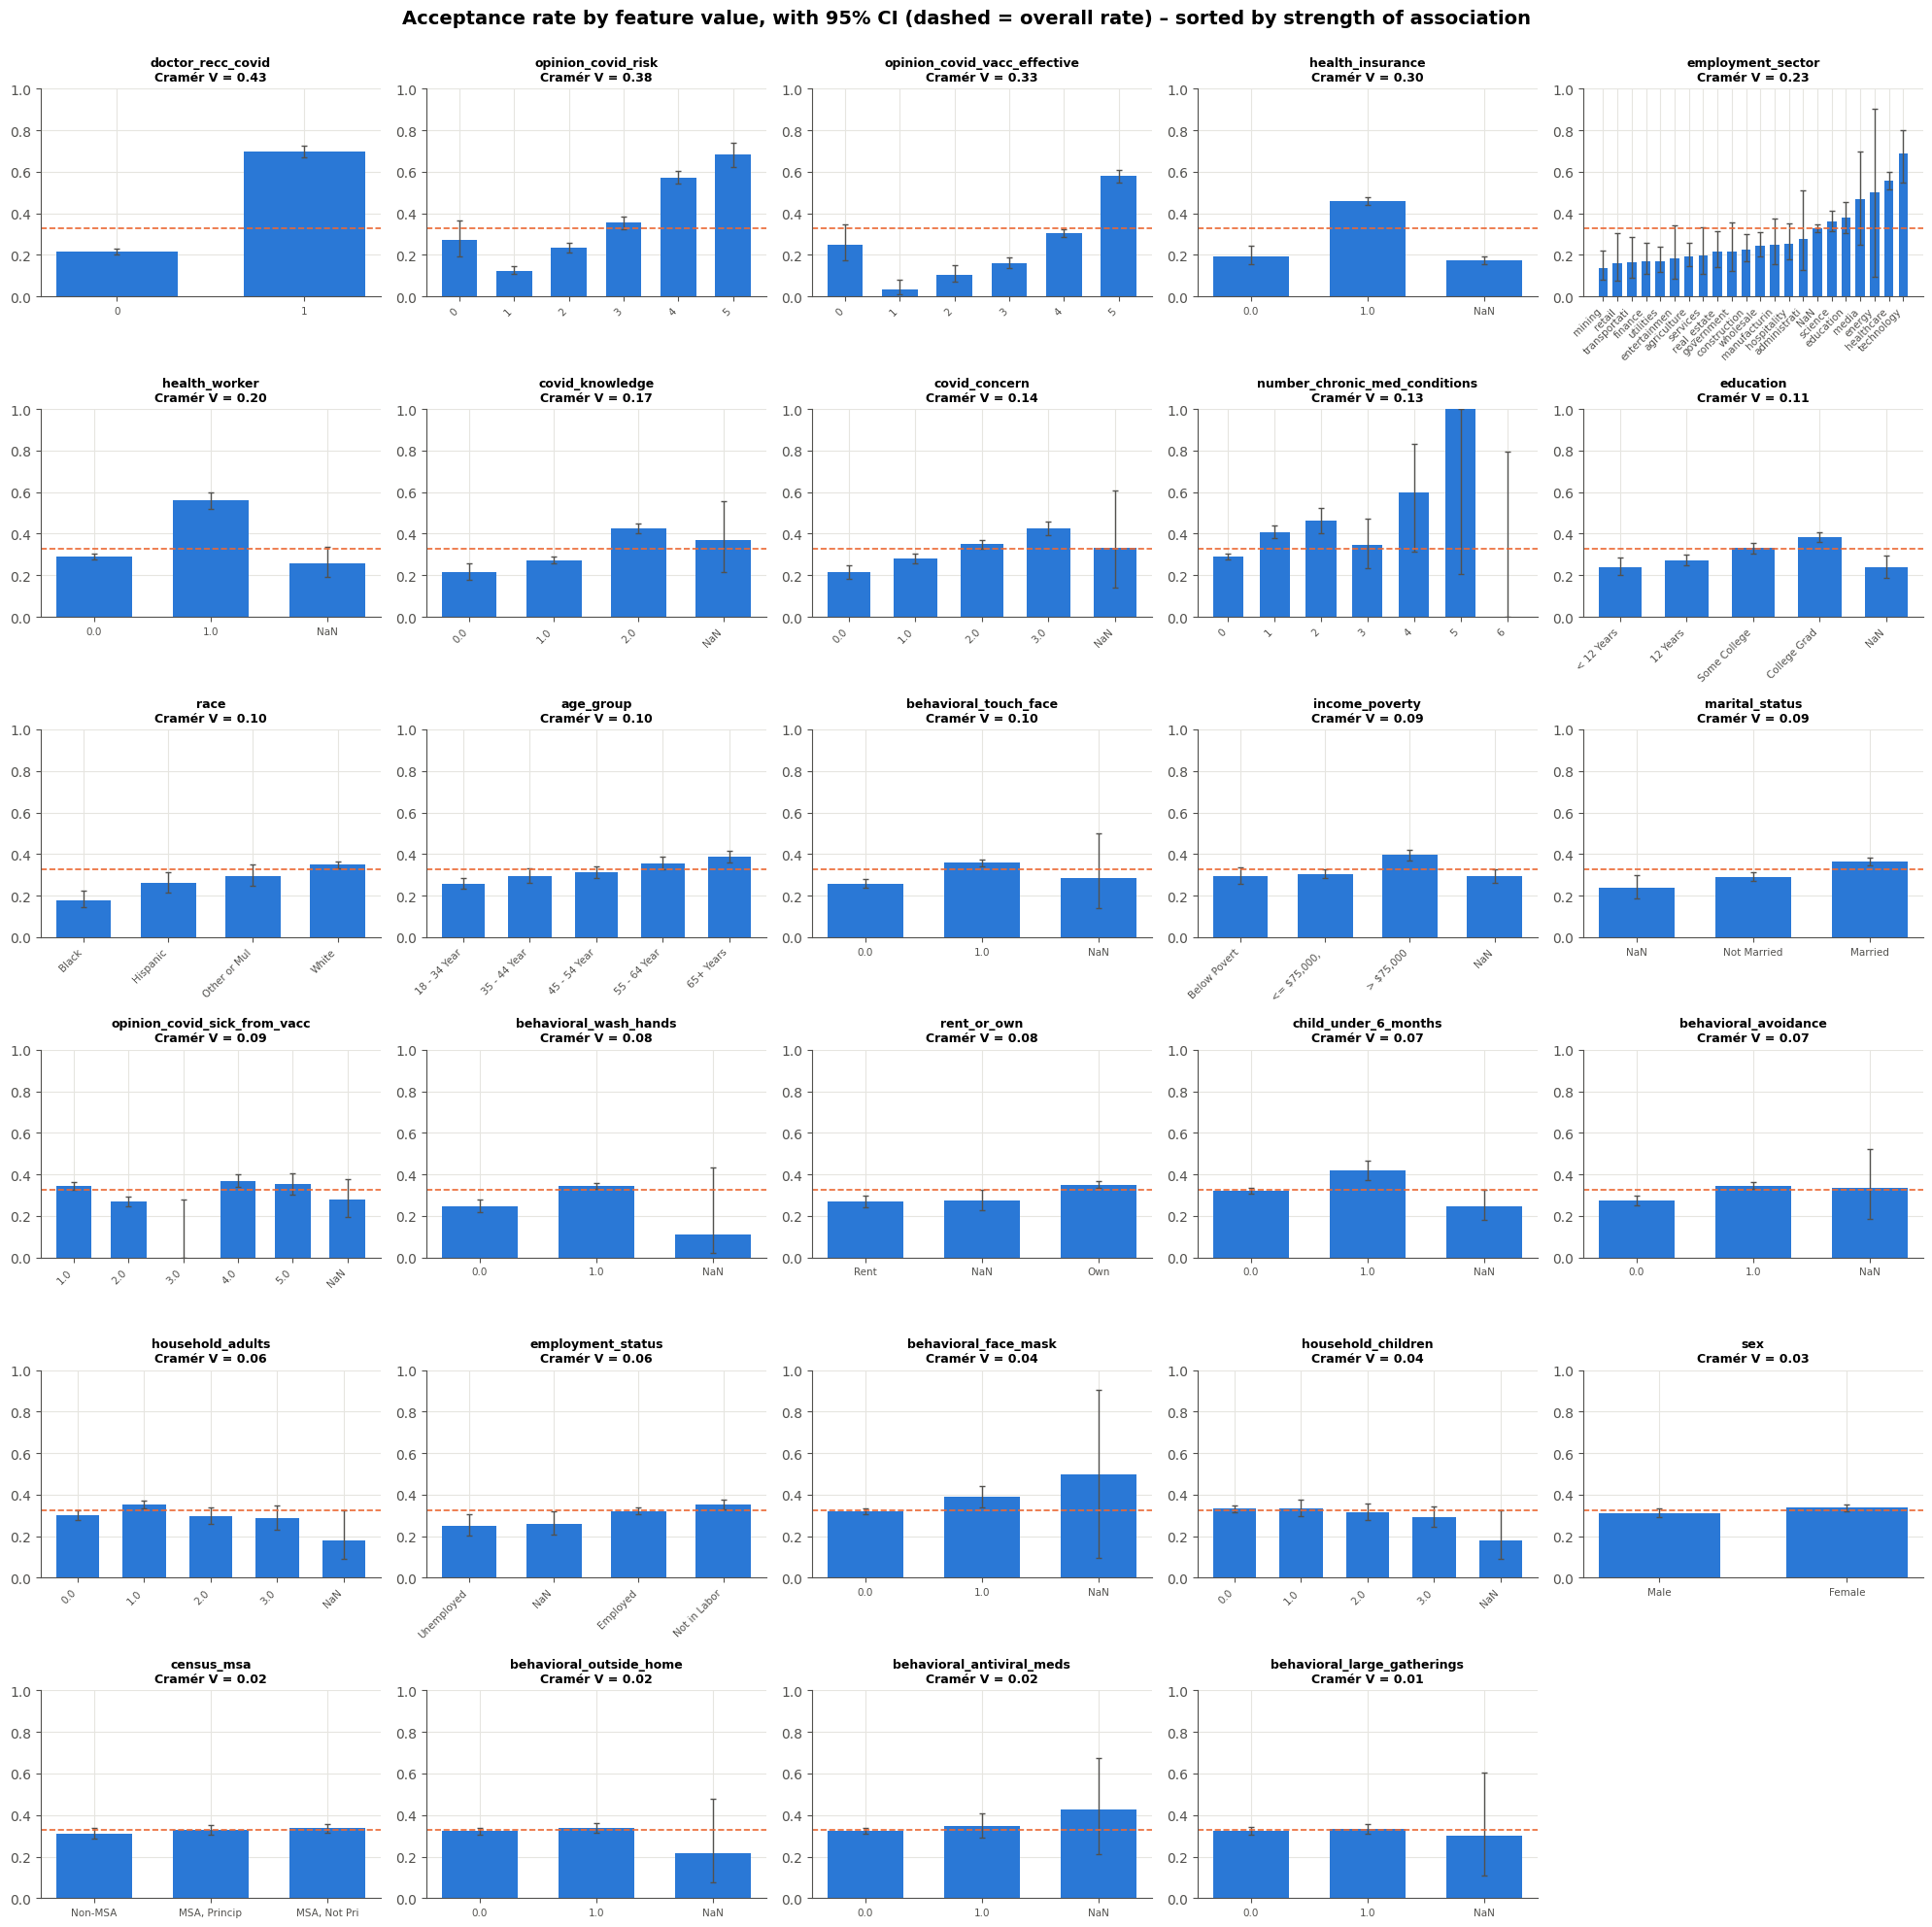

In [21]:
def wilson(k, n, z=1.96):
    # 95% Wilson confidence interval for a proportion.
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half

def cramers_v(x, y):
    ct = pd.crosstab(x.fillna('NaN').astype(str), y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

assoc = pd.Series({c: cramers_v(train_raw[c], train_raw[TARGET]) for c in FEATURES}).sort_values(ascending=False)
base_rate = train_raw[TARGET].mean()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.3 * n_rows))
for ax, c in zip(axes.flat, assoc.index):
    s = train_raw[c].fillna('NaN').astype(str)
    g = train_raw.groupby(s)[TARGET].agg(['sum', 'size'])
    if c in ['age_group', 'education', 'income_poverty']:
        order = {'age_group': AGE_ORDER, 'education': EDU_ORDER, 'income_poverty': INC_ORDER}[c]
        g = g.reindex([o for o in order + ['NaN'] if o in g.index])
    elif c not in CATEGORICAL:
        g = g.sort_index()
    else:
        g = g.sort_values('sum', key=lambda _: g['sum'] / g['size'])
    rate = g['sum'] / g['size']
    lo, hi = wilson(g['sum'], g['size'])
    x = np.arange(len(g))
    ax.bar(x, rate, color=BLUE, width=0.65)
    ax.errorbar(x, rate, yerr=[rate - lo, hi - rate], fmt='none', ecolor=INK2, elinewidth=1, capsize=2)
    ax.axhline(base_rate, color=ORANGE, lw=1.2, ls='--')
    ax.set_xticks(x, [str(l)[:12] for l in g.index], rotation=45 if len(g) > 3 else 0,
                  ha='right' if len(g) > 3 else 'center', fontsize=7.5)
    ax.set_ylim(0, 1); ax.set_title(f'{c}\nCramér V = {assoc[c]:.2f}', fontsize=9)
for ax in list(axes.flat)[len(assoc):]:
    ax.axis('off')
plt.suptitle('Acceptance rate by feature value, with 95% CI (dashed = overall rate) – sorted by strength of association',
             y=1.0, fontsize=14, fontweight='bold')
plt.tight_layout(); savefig('03_bivariate'); plt.show()

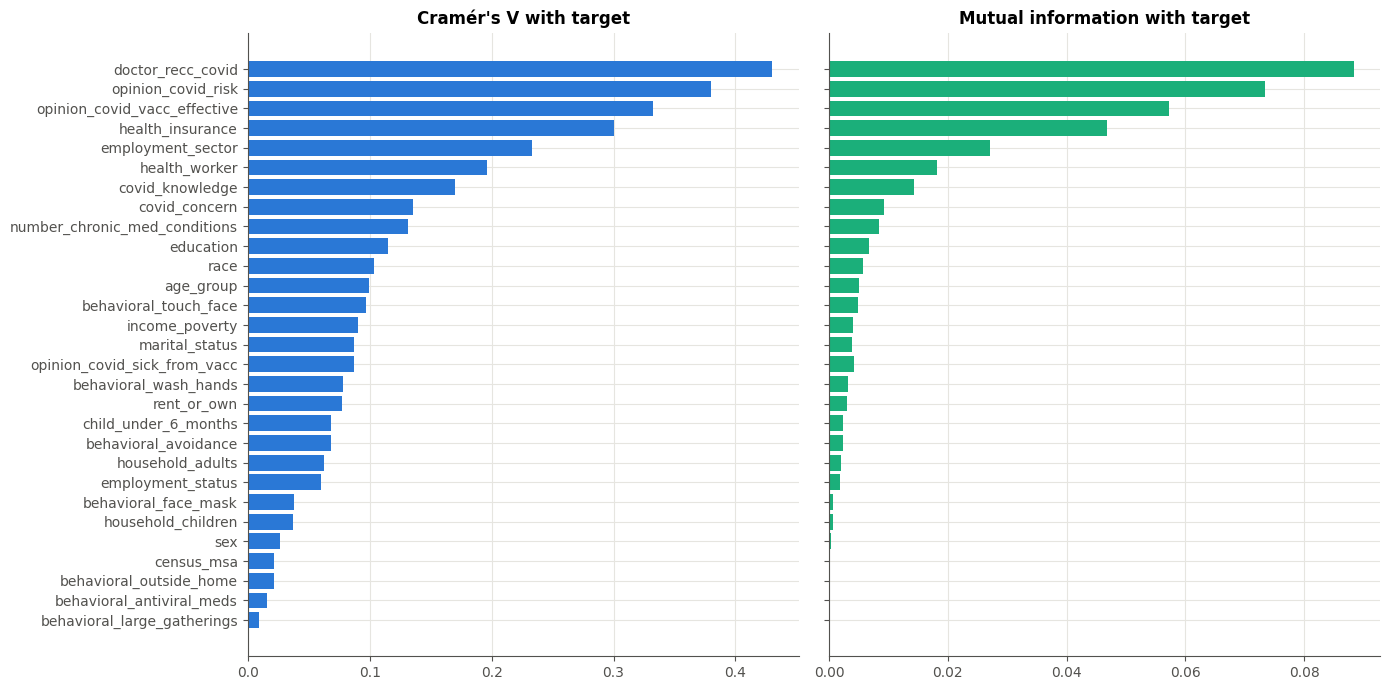

In [22]:
# Two complementary association rankings: Cramér's V (chi-square based) and mutual information
enc = train_raw[FEATURES].astype(str).apply(lambda s: s.astype('category').cat.codes)   # NaN becomes its own level
mi = pd.Series(mutual_info_classif(enc, train_raw[TARGET], discrete_features=True, random_state=RANDOM_STATE),
               index=FEATURES)
rank = pd.DataFrame({'cramers_v': assoc, 'mutual_info': mi}).sort_values('cramers_v')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
axes[0].barh(rank.index, rank['cramers_v'], color=BLUE); axes[0].set_title("Cramér's V with target")
axes[1].barh(rank.index, rank['mutual_info'], color=AQUA); axes[1].set_title('Mutual information with target')
plt.tight_layout(); savefig('03_association_rank'); plt.show()

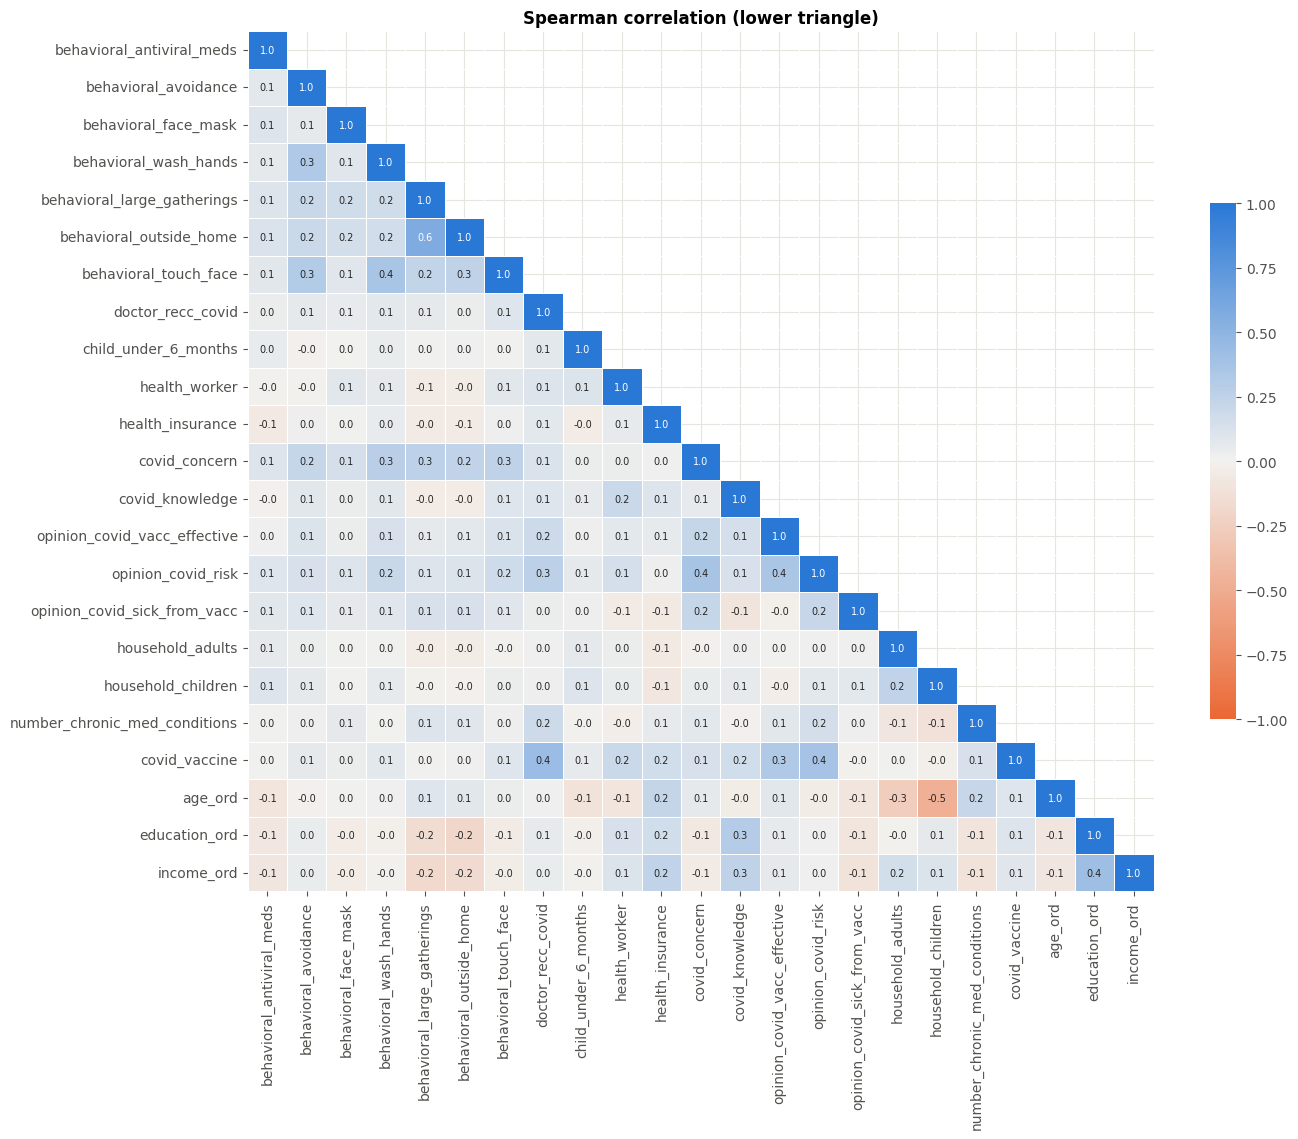

Strongest pairwise correlations:
behavioral_outside_home  behavioral_large_gatherings     0.58
age_ord                  household_children             -0.47
covid_vaccine            doctor_recc_covid               0.43
income_ord               education_ord                   0.42
covid_vaccine            opinion_covid_risk              0.38
opinion_covid_risk       covid_concern                   0.37
behavioral_touch_face    behavioral_wash_hands           0.36
opinion_covid_risk       opinion_covid_vacc_effective    0.35
dtype: float64


In [23]:
# Spearman correlation among ordinal / binary features (and the target) – looks for redundancy
num_view = train_raw[BINARY + ORDINAL_NUM + [TARGET]].copy()
num_view[OPINION[:2]] = num_view[OPINION[:2]].replace(0, np.nan)
num_view['age_ord'] = train_raw['age_group'].map({a: i for i, a in enumerate(AGE_ORDER)})
num_view['education_ord'] = train_raw['education'].map({a: i for i, a in enumerate(EDU_ORDER)})
num_view['income_ord'] = train_raw['income_poverty'].map({a: i for i, a in enumerate(INC_ORDER)})
corr = num_view.corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 11.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIV_CMAP, center=0, vmin=-1, vmax=1, annot=True, fmt='.1f',
            annot_kws={'size': 7}, linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'shrink': 0.6})
ax.set_title('Spearman correlation (lower triangle)'); plt.tight_layout(); savefig('03_correlation'); plt.show()

pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().sort_values(key=abs, ascending=False)
print('Strongest pairwise correlations:'); print(pairs.head(8).round(2))

**Strongest predictors of acceptance:** a **doctor's recommendation** (≈70 % vs 22 % acceptance), the person's **opinion of vaccine effectiveness**
and **perceived risk of COVID**, then **health worker**, **health insurance**, COVID concern and age. Socio-demographic variables
(race, sex, marital status, household size, MSA) matter much less. Correlations between features are moderate (|ρ| ≤ ≈0.6, e.g. among the
behavioural questions, and `household_children`–`child_under_6_months`), so multicollinearity is not severe – but L2/elastic-net
regularisation is still sensible for logistic regression.

### 3.8 Interactions

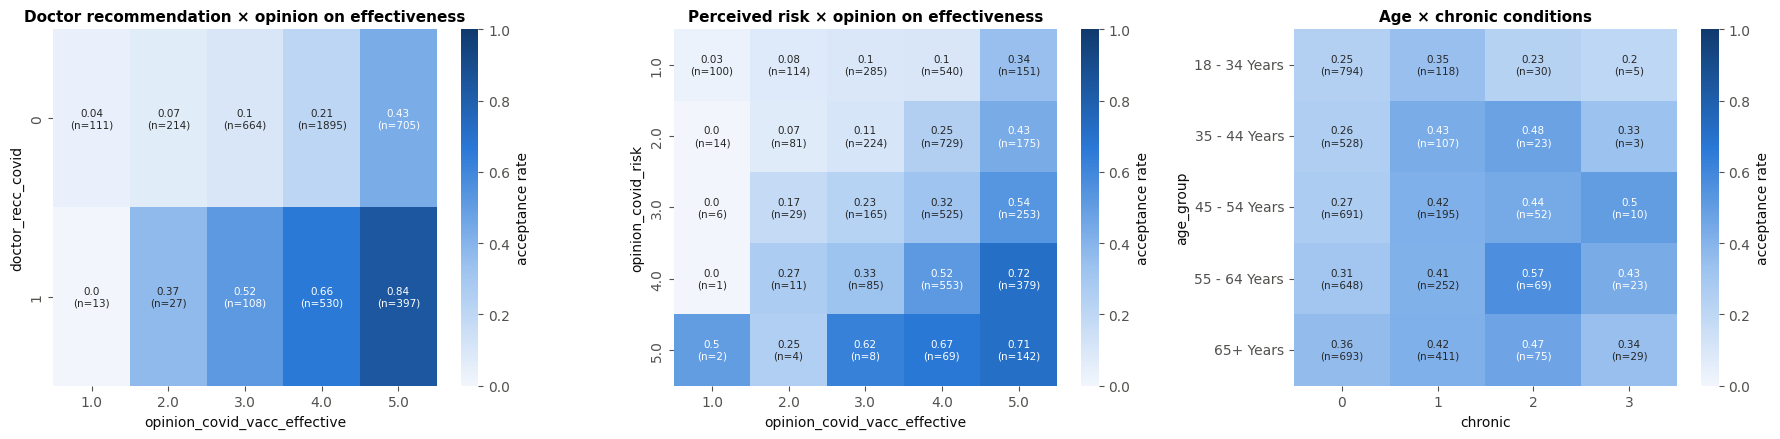

In [24]:
d = train_raw.assign(opinion_covid_vacc_effective=train_raw['opinion_covid_vacc_effective'].replace(0, np.nan),
                     opinion_covid_risk=train_raw['opinion_covid_risk'].replace(0, np.nan),
                     chronic=train_raw['number_chronic_med_conditions'].clip(upper=3))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (r, c, title) in zip(axes, [('doctor_recc_covid', 'opinion_covid_vacc_effective', 'Doctor recommendation × opinion on effectiveness'),
                                    ('opinion_covid_risk', 'opinion_covid_vacc_effective', 'Perceived risk × opinion on effectiveness'),
                                    ('age_group', 'chronic', 'Age × chronic conditions')]):
    pt = d.pivot_table(index=r, columns=c, values=TARGET, aggfunc='mean')
    n = d.pivot_table(index=r, columns=c, values=TARGET, aggfunc='size')
    if r == 'age_group':
        pt, n = pt.reindex(AGE_ORDER), n.reindex(AGE_ORDER)
    annot = pt.round(2).astype(str) + '\n(n=' + n.fillna(0).astype(int).astype(str) + ')'
    sns.heatmap(pt, annot=annot, fmt='', cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, annot_kws={'size': 7.5},
                cbar_kws={'label': 'acceptance rate'})
    ax.set_title(title, fontsize=11)
plt.tight_layout(); savefig('03_interactions'); plt.show()

* Doctor recommendation and belief in effectiveness **reinforce each other**: from ≈3 % (doctor did not recommend, "not at all effective")
  to ≈87 % (recommended, "very effective"). Interactions like this favour tree-based models, but the effects are mostly monotone and
  additive on the log-odds scale, so logistic regression should also be competitive.
* Age and chronic conditions raise acceptance *and* hospitalisation risk – the people the model finds most likely to accept are often the
  ones where vaccination saves the most money.

### 3.9 Cost-driver view: where is the money?

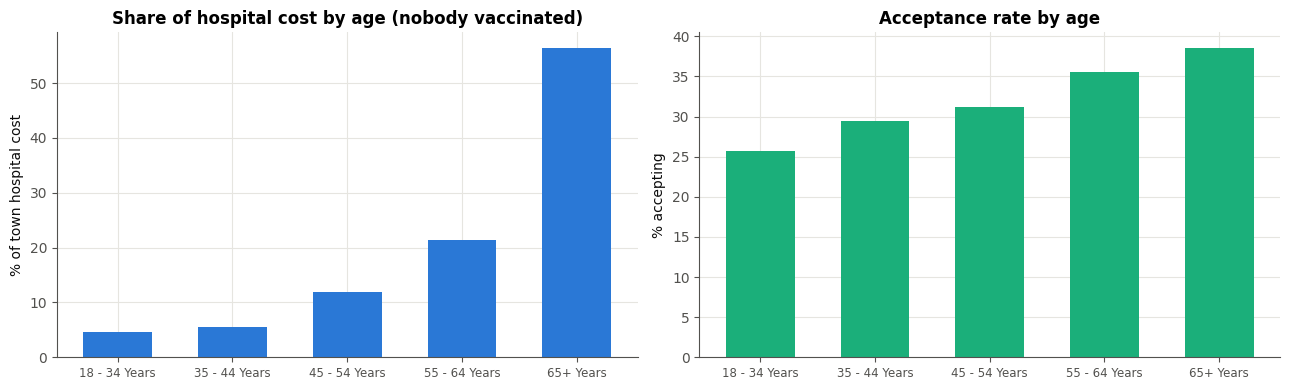

,people,accept_rate,mean_risk,hosp_cost_if_nobody_vacc,share_of_hosp_cost
age_group,,,,,
18 - 34 Years,947,0.258,0.019,735654.448,0.047
35 - 44 Years,661,0.295,0.032,872196.958,0.055
45 - 54 Years,948,0.312,0.049,1885498.185,0.119
55 - 64 Years,992,0.356,0.083,3381346.362,0.214
65+ Years,1208,0.386,0.180,8911557.993,0.565


In [25]:
tr_view = train_raw.assign(p_hosp=MAIN.p_unvacc(train_raw))
g = tr_view.groupby('age_group').agg(people=(TARGET, 'size'), accept_rate=(TARGET, 'mean'), mean_risk=('p_hosp', 'mean'),
                                     hosp_cost_if_nobody_vacc=('p_hosp', lambda p: HOSP_COST * p.sum())).reindex(AGE_ORDER)
g['share_of_hosp_cost'] = g['hosp_cost_if_nobody_vacc'] / g['hosp_cost_if_nobody_vacc'].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(g.index, g['share_of_hosp_cost'] * 100, color=BLUE, width=0.6)
axes[0].set_ylabel('% of town hospital cost'); axes[0].set_title('Share of hospital cost by age (nobody vaccinated)')
axes[1].bar(g.index, g['accept_rate'] * 100, color=AQUA, width=0.6)
axes[1].set_ylabel('% accepting'); axes[1].set_title('Acceptance rate by age')
for ax in axes:
    ax.tick_params(axis='x', labelsize=8.5)
plt.tight_layout(); savefig('03_cost_drivers'); plt.show()
g.round(3)

The 65+ group (≈25 % of residents) generates ≈60 % of the potential hospital bill. Getting the *elderly* decisions right matters far more than
getting the *young* ones right – exactly what the personal threshold encodes.

### 3.10 EDA → pre-processing decisions

| Finding | Decision |
|---|---|
| `respondent_id` is random | drop |
| 0 in opinion scales = disguised missing | recode to NaN |
| `employment_sector` missing for non-employed | new category `not_employed` |
| Missingness is informative (lower acceptance) | test "Missing" category + missing-indicator flags + count of missing answers |
| Ordered categories (age, education, income) | test ordinal encoding vs one-hot |
| Rare `employment_sector` levels | group levels with < 30 people (`min_frequency`) |
| Long tail of chronic conditions | top-code at 3 (binning) |
| Many related behaviour / opinion questions | engineered `behaviour_score` (sum) and `vacc_attitude` (effective + risk − worried) |
| Imbalance 33/67 | no resampling – keep probabilities calibrated; handle via cost-based thresholds |
| No train/test shift | standard stratified CV is a good proxy for the test set |

## 4. Pre-processing
### 4.1 Cleaning + feature engineering (row-wise, so it cannot leak information between folds)
All steps below only look at one row at a time, so they can safely run *before* the train/validation split. Everything that **learns**
from data (imputation values, scaling, rare-category grouping) lives inside a scikit-learn `Pipeline` and is therefore re-fitted inside every
cross-validation fold – no data leakage.

In [26]:
ENGINEERED = ['n_missing', 'behaviour_score', 'vacc_attitude', 'dont_know_any', 'age_ord', 'education_ord', 'income_ord']

def clean_features(df):
    # Row-wise cleaning + feature engineering decided in the EDA (no statistics learned from data).
    d = df[FEATURES].copy()
    zero_coded = d[OPINION[:2]].eq(0)                                  # 0 is not a valid answer on a 1-5 scale
    d['n_missing'] = d.isna().sum(axis=1) + zero_coded.sum(axis=1)     # engagement proxy
    d[OPINION[:2]] = d[OPINION[:2]].mask(zero_coded)                   # disguised missing -> NaN
    d[CATEGORICAL] = d[CATEGORICAL].astype(object)
    not_employed = d['employment_status'].isin(['Not in Labor Force', 'Unemployed'])
    d.loc[not_employed & d['employment_sector'].isna(), 'employment_sector'] = 'not_employed'   # structural missing
    d['census_msa'] = d['census_msa'].str.replace(r'\s+', ' ', regex=True)
    d['number_chronic_med_conditions'] = d['number_chronic_med_conditions'].clip(upper=3)    # top-code (binning)
    d['behaviour_score'] = d[BEHAVIOURAL].sum(axis=1, min_count=1)                          # 0-7 protective behaviours
    d['vacc_attitude'] = (d['opinion_covid_vacc_effective'] + d['opinion_covid_risk']
                          - d['opinion_covid_sick_from_vacc'])
    d['dont_know_any'] = d[OPINION].eq(3).any(axis=1).astype(int)
    d['age_ord'] = d['age_group'].map({a: i for i, a in enumerate(AGE_ORDER)})
    d['education_ord'] = d['education'].map({a: i for i, a in enumerate(EDU_ORDER)})
    d['income_ord'] = d['income_poverty'].map({a: i for i, a in enumerate(INC_ORDER)})
    return d

X_all = train_raw[FEATURES].copy()
y_all = train_raw[TARGET].copy()
X_test = test_raw[FEATURES].copy()
clean_features(X_all).head()

,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,child_under_6_months,health_worker,health_insurance,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,n_missing,behaviour_score,vacc_attitude,dont_know_any,age_ord,education_ord,income_ord
0,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,NaN,45 - 54 Years,12 Years,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Principle City",3.0,2.0,0,4.0,4.0,2.0,construction,1,1,4.0,6.0,0,2,1.0,1.0
1,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,45 - 54 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,0,5.0,2.0,1.0,education,0,0,3.0,6.0,0,2,3.0,1.0
2,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Not Married,Own,Employed,"MSA, Not Principle City",0.0,0.0,0,2.0,2.0,5.0,wholesale,3,1,0.0,-1.0,0,2,2.0,1.0
3,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,NaN,65+ Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,1,3.0,3.0,2.0,not_employed,1,2,3.0,4.0,1,4,3.0,1.0
4,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,18 - 34 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,"MSA, Not Principle City",0.0,0.0,0,3.0,2.0,2.0,wholesale,0,0,1.0,3.0,1,0,3.0,1.0


### 4.2 Four pre-processing options
| Option | Imputation | Encoding | Extra |
|---|---|---|---|
| **P1 basic** | median (numeric) / most-frequent (categorical) | one-hot all categoricals | – |
| **P2 missing-aware** | median + **missing-indicator** columns; categorical NaN → **"Missing"** level | one-hot | – |
| **P3 ordinal + FE** | as P2 | **ordinal codes** for age / education / income, one-hot (rare levels < 30 grouped) for nominal | engineered features |
| **P4 binned opinions** | as P3 | as P3, but opinion scales **binned** into lower (1–2) / don't know (3) / upper (4–5) and one-hot encoded | engineered features |

Numeric columns are standardised (needed for regularised logistic regression; harmless for trees).

In [27]:
NUM_BASE = ORDINAL_NUM + BINARY
NOMINAL = ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

def ohe(min_frequency=None):
    return OneHotEncoder(handle_unknown='infrequent_if_exist' if min_frequency else 'ignore',
                         min_frequency=min_frequency, sparse_output=False)

def bin_opinions(X):
    # Bin the 1-5 opinion scales into lower (1-2) / dont_know (3) / upper (4-5) end of the scale.
    mapping = {1: 'lower', 2: 'lower', 3: 'dont_know', 4: 'upper', 5: 'upper'}
    return pd.DataFrame(X).apply(lambda s: s.map(mapping)).astype(object)

def num_pipe(indicator):
    return Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=indicator)), ('sc', StandardScaler())])

def cat_pipe(strategy, min_frequency=None):
    imp = SimpleImputer(strategy='constant', fill_value='Missing') if strategy == 'missing' \
        else SimpleImputer(strategy='most_frequent')
    return Pipeline([('imp', imp), ('oh', ohe(min_frequency))])

def make_preprocessor(option):
    if option == 'P1_basic':
        parts = [('num', num_pipe(False), NUM_BASE), ('cat', cat_pipe('mode'), CATEGORICAL)]
    elif option == 'P2_missing_aware':
        parts = [('num', num_pipe(True), NUM_BASE), ('cat', cat_pipe('missing'), CATEGORICAL)]
    elif option == 'P3_ordinal_fe':
        parts = [('num', num_pipe(True), NUM_BASE + ENGINEERED), ('cat', cat_pipe('missing', 30), NOMINAL)]
    elif option == 'P4_binned':
        non_opinion = [c for c in NUM_BASE if c not in OPINION]
        parts = [('num', num_pipe(True), non_opinion + ENGINEERED),
                 ('op', Pipeline([('bin', FunctionTransformer(bin_opinions, feature_names_out='one-to-one')),
                                  ('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
                                  ('oh', ohe())]), OPINION),
                 ('cat', cat_pipe('missing', 30), NOMINAL)]
    else:
        raise ValueError(option)
    return ColumnTransformer(parts, remainder='drop')

def make_pipe(option, clf):
    # Full model = row-wise cleaning -> learned pre-processing -> classifier.
    return Pipeline([('clean', FunctionTransformer(clean_features)), ('prep', make_preprocessor(option)), ('clf', clf)])

PREP_OPTIONS = ['P1_basic', 'P2_missing_aware', 'P3_ordinal_fe', 'P4_binned']
for opt in PREP_OPTIONS:
    n = make_pipe(opt, LogisticRegression()).fit(X_all.head(800), y_all.head(800))[:-1].transform(X_all.head(5)).shape[1]
    print(f'{opt:18s} -> {n} model inputs')

P1_basic           -> 68 model inputs
P2_missing_aware   -> 90 model inputs
P3_ordinal_fe      -> 70 model inputs
P4_binned          -> 75 model inputs


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_mo

### 4.3 Hold-out split and the evaluation helpers
We keep **20 % of the labelled data as an untouched hold-out set** (never used for tuning or model choice) and do all comparison and tuning on the
remaining 80 % ("development set") with **repeated stratified 5-fold cross-validation** (5 folds × 2 repeats = 10 estimates per model),
which also gives us the size of the random variation (standard deviation across folds).

In [28]:
X_dev, X_hold, y_dev, y_hold = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
print('development:', X_dev.shape, f'(accept rate {y_dev.mean():.3f})  | hold-out:', X_hold.shape,
      f'(accept rate {y_hold.mean():.3f})')

CV_SPLITS, CV_REPEATS = 5, 2
REPEATED_CV = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=RANDOM_STATE)
TUNE_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

STRATEGIES = ['thr 0.5', 'single thr', 'personal thr']

def decide(prob, X, strategy, scenario=MAIN):
    # Turn acceptance probabilities into send (1) / don't send (0) decisions.
    if strategy == 'thr 0.5':
        t = 0.5
    elif strategy == 'single thr':
        t = scenario.global_threshold()
    elif strategy == 'personal thr':
        t = scenario.personal_threshold(X)
    else:
        raise ValueError(strategy)
    return (np.asarray(prob) >= t).astype(int)

def evaluate_probs(y, prob, X, scenario=MAIN):
    # Probability metrics + task metric ($ per resident) for each decision strategy.
    y = np.asarray(y)
    nobody = scenario.cost(y, np.zeros_like(y), X)
    oracle = scenario.cost(y, y, X)
    out = {'ROC-AUC': roc_auc_score(y, prob), 'log-loss': log_loss(y, prob), 'Brier': brier_score_loss(y, prob),
           'F1@0.5': f1_score(y, np.asarray(prob) >= 0.5), 'accuracy@0.5': accuracy_score(y, np.asarray(prob) >= 0.5)}
    for s in STRATEGIES:
        c = scenario.cost(y, decide(prob, X, s, scenario), X)
        out[f'$/resident [{s}]'] = c / len(y)
        out[f'% saving captured [{s}]'] = 100 * (nobody - c) / (nobody - oracle)
    return out

def cv_evaluate(model, X, y, cv=REPEATED_CV, name=''):
    # Repeated CV. Returns per-fold metrics and out-of-fold probabilities of the first repeat.
    rows, oof = [], np.full(len(y), np.nan)
    for k, (tr, va) in enumerate(cv.split(X, y)):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        if k < CV_SPLITS:
            oof[va] = p
        rows.append({'model': name, 'fold': k, **evaluate_probs(y.iloc[va], p, X.iloc[va])})
    return pd.DataFrame(rows), oof

def summarise(folds, cols=None):
    cols = cols or ['ROC-AUC', 'log-loss', '$/resident [thr 0.5]', '$/resident [single thr]', '$/resident [personal thr]',
                    '% saving captured [personal thr]']
    g = folds.groupby('model')[cols]
    return g.mean().round(4).astype(str) + ' ± ' + g.std().round(4).astype(str)

development: (3804, 29) (accept rate 0.327)  | hold-out: (952, 29) (accept rate 0.327)


### 4.4 Which pre-processing works best? (logistic regression and LightGBM, default settings)

In [29]:
t0 = time.time()
base_models = {
    'LogReg': lambda: LogisticRegression(C=0.1, max_iter=5000),
    'LightGBM': lambda: LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                                       random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
}
prep_folds = []
for mname, mk in base_models.items():
    for opt in PREP_OPTIONS:
        f, _ = cv_evaluate(make_pipe(opt, mk()), X_dev, y_dev, name=f'{mname} | {opt}')
        f['family'], f['prep'] = mname, opt
        prep_folds.append(f)
prep_folds = pd.concat(prep_folds, ignore_index=True)
print(f'done in {time.time() - t0:.0f}s')
summarise(prep_folds)

/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/linear_mo

done in 66s


,ROC-AUC,log-loss,$/resident [thr 0.5],$/resident [single thr],$/resident [personal thr],% saving captured [personal thr]
model,,,,,,
LightGBM | P1_basic,0.8325 ± 0.0157,0.4653 ± 0.02,3202.9487 ± 70.7943,3175.3662 ± 71.1007,3100.8983 ± 83.1353,63.0309 ± 3.5246
LightGBM | P2_missing_aware,0.8606 ± 0.0103,0.428 ± 0.0159,3149.3829 ± 65.9189,3118.4536 ± 65.809,3052.21 ± 67.1089,67.5746 ± 2.5617
LightGBM | P3_ordinal_fe,0.8618 ± 0.0108,0.4267 ± 0.0159,3151.9198 ± 59.9869,3118.4834 ± 64.5713,3048.3761 ± 68.2322,67.9524 ± 2.3638
LightGBM | P4_binned,0.8594 ± 0.0119,0.4289 ± 0.0169,3141.1165 ± 59.9254,3123.193 ± 61.8003,3060.8321 ± 66.6388,66.7813 ± 2.8465
LogReg | P1_basic,0.8352 ± 0.0142,0.4582 ± 0.0162,3194.2989 ± 62.9858,3163.2367 ± 58.2003,3097.4248 ± 83.3626,63.3573 ± 3.5211
LogReg | P2_missing_aware,0.8611 ± 0.0107,0.4266 ± 0.0153,3143.4005 ± 59.9278,3109.7612 ± 58.4245,3055.503 ± 64.9713,67.283 ± 2.3685
LogReg | P3_ordinal_fe,0.8609 ± 0.0113,0.4268 ± 0.0164,3139.1286 ± 68.7603,3111.1589 ± 59.6712,3059.3934 ± 67.7639,66.9254 ± 2.465
LogReg | P4_binned,0.8592 ± 0.0117,0.4288 ± 0.0169,3143.6195 ± 62.5644,3117.4327 ± 64.3024,3053.155 ± 71.2656,67.5011 ± 2.798


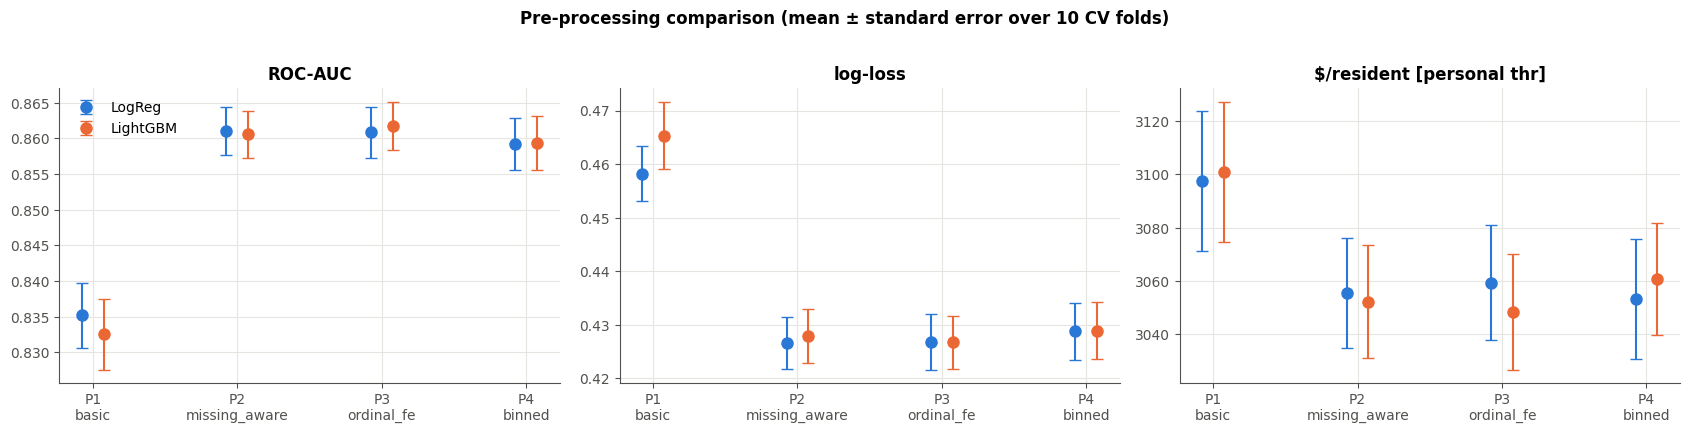

Best pre-processing per model family (lowest mean cost): {'LogReg': 'P4_binned', 'LightGBM': 'P3_ordinal_fe'}


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, metric in zip(axes, ['ROC-AUC', 'log-loss', '$/resident [personal thr]']):
    agg = prep_folds.groupby(['family', 'prep'])[metric].agg(['mean', 'std']).reset_index()
    x = np.arange(len(PREP_OPTIONS))
    for i, (fam, col) in enumerate(zip(base_models, [BLUE, ORANGE])):
        a = agg[agg['family'] == fam].set_index('prep').reindex(PREP_OPTIONS)
        ax.errorbar(x + (i - 0.5) * 0.15, a['mean'], yerr=a['std'] / np.sqrt(CV_SPLITS * CV_REPEATS),
                    fmt='o', color=col, capsize=4, ms=8, label=fam)
    ax.set_xticks(x, [p.replace('_', '\n', 1) for p in PREP_OPTIONS]); ax.set_title(metric)
axes[0].legend()
plt.suptitle('Pre-processing comparison (mean ± standard error over 10 CV folds)', fontweight='bold', y=1.02)
plt.tight_layout(); savefig('04_preprocessing'); plt.show()

prep_mean = prep_folds.groupby(['family', 'prep'])[['log-loss', '$/resident [personal thr]']].mean()
BEST_PREP = {fam: prep_mean.loc[fam]['$/resident [personal thr]'].idxmin() for fam in base_models}
print('Best pre-processing per model family (lowest mean cost):', BEST_PREP)

**Result.** The *missing-aware* options (P2–P4) beat plain imputation (P1) clearly and for both model families: ROC-AUC rises from
≈0.835 to ≈0.86, log-loss falls from ≈0.46 to ≈0.43 and the town saves roughly **\$40–50 per resident** (≈\$200 000 for the 4 749-person test town).
This confirms the EDA finding that *not answering a question* is itself informative. The differences **between** P2, P3 and P4 are smaller than the
fold-to-fold noise (standard error ≈ \$20), so we simply keep, for each family, the option with the lowest mean cost (printed above) and use it for all
later models of that family (the LightGBM choice is used for every one-hot-based tree model).

## 5. Modelling and hyper-parameter tuning
### 5.1 Candidate models
* **Logistic regression** (elastic-net): interpretable baseline, naturally well calibrated.
* **Random forest**: bagged trees, robust; its probabilities are known to be squeezed towards 0.5, so we also test an **isotonic-calibrated** version.
* **XGBoost**, **LightGBM**: gradient-boosted trees, capture the interactions seen in the EDA.
* **CatBoost**: boosting with *native* categorical handling (ordered target statistics) – no one-hot needed.
* **Soft-voting ensemble** of LR + XGBoost + LightGBM + CatBoost: averaging diverse models usually improves calibration and stability.

**Tuning objective.** Hyper-parameters are tuned with `RandomizedSearchCV` (5-fold) on **log-loss**. Our decisions depend on the
*probability* values (they are compared with personal thresholds), so we want the most accurate, calibrated probabilities; log-loss is a
proper scoring rule that rewards exactly that, and it is much smoother than the dollar cost (which jumps when a probability crosses a
threshold). The dollar cost is then used to **compare and select** models.

In [31]:
from scipy.stats import loguniform, randint, uniform

def make_lr(C=0.1, l1_ratio=0.0):
    # Elastic-net logistic regression that works on old and new scikit-learn versions.
    if SK_VERSION >= (1, 8):
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver='saga', max_iter=5000)
    return LogisticRegression(C=C, l1_ratio=l1_ratio, penalty='elasticnet', solver='saga', max_iter=5000)


CB_FEATURES = NUM_BASE + ENGINEERED + CATEGORICAL

class CatBoostSK(ClassifierMixin, BaseEstimator):
    # Small scikit-learn wrapper around CatBoost (native categorical features, clone-safe on all sklearn versions).
    def __init__(self, iterations=500, learning_rate=0.05, depth=5, l2_leaf_reg=3.0, thread_count=-1,
                 random_state=RANDOM_STATE):
        self.iterations, self.learning_rate, self.depth = iterations, learning_rate, depth
        self.l2_leaf_reg, self.thread_count, self.random_state = l2_leaf_reg, thread_count, random_state

    def _frame(self, X):
        X = X[CB_FEATURES].copy()
        X[CATEGORICAL] = X[CATEGORICAL].fillna('Missing').astype(str)
        return X

    def fit(self, X, y):
        self.model_ = CatBoostClassifier(iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth,
                                         l2_leaf_reg=self.l2_leaf_reg, thread_count=self.thread_count,
                                         random_seed=self.random_state, cat_features=CATEGORICAL, verbose=0,
                                         allow_writing_files=False)
        self.model_.fit(self._frame(X), np.asarray(y))
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self._frame(X))

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]

    def shap_values(self, X):
        Xf = self._frame(X)
        sv = self.model_.get_feature_importance(Pool(Xf, cat_features=CATEGORICAL), type='ShapValues')
        return sv[:, :-1], sv[:, -1], Xf

def catboost_pipe(**kw):
    return Pipeline([('clean', FunctionTransformer(clean_features)), ('clf', CatBoostSK(**kw))])


SEARCH_SPACES = {
    'Logistic Regression': (make_pipe(BEST_PREP['LogReg'], make_lr()),
                            {'clf__C': loguniform(1e-3, 10), 'clf__l1_ratio': uniform(0, 1)}, 15),
    'Random Forest': (make_pipe(BEST_PREP['LightGBM'], RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
                      {'clf__n_estimators': randint(200, 600), 'clf__max_depth': [None, 6, 8, 10, 14, 18],
                       'clf__min_samples_leaf': randint(1, 20), 'clf__max_features': ['sqrt', 0.2, 0.35, 0.5]}, 15),
    'XGBoost': (make_pipe(BEST_PREP['LightGBM'], XGBClassifier(eval_metric='logloss', tree_method='hist', n_jobs=1,
                                                               random_state=RANDOM_STATE)),
                {'clf__n_estimators': randint(150, 800), 'clf__learning_rate': loguniform(0.01, 0.2),
                 'clf__max_depth': randint(2, 7), 'clf__subsample': uniform(0.6, 0.4),
                 'clf__colsample_bytree': uniform(0.4, 0.6), 'clf__min_child_weight': randint(1, 12),
                 'clf__reg_lambda': loguniform(0.1, 20)}, 25),
    'LightGBM': (make_pipe(BEST_PREP['LightGBM'], LGBMClassifier(subsample_freq=1, n_jobs=1, verbose=-1,
                                                                 random_state=RANDOM_STATE)),
                 {'clf__n_estimators': randint(150, 800), 'clf__learning_rate': loguniform(0.01, 0.2),
                  'clf__num_leaves': randint(4, 48), 'clf__min_child_samples': randint(10, 100),
                  'clf__subsample': uniform(0.6, 0.4), 'clf__colsample_bytree': uniform(0.4, 0.6),
                  'clf__reg_lambda': loguniform(0.01, 20)}, 25),
    'CatBoost': (catboost_pipe(thread_count=1),
                 {'clf__iterations': randint(300, 900), 'clf__learning_rate': loguniform(0.02, 0.15),
                  'clf__depth': randint(3, 8), 'clf__l2_leaf_reg': loguniform(1, 20)}, 10),
}

TUNED, tuning_rows = {}, []
for name, (pipe, space, n_iter) in SEARCH_SPACES.items():
    t0 = time.time()
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring='neg_log_loss', cv=TUNE_CV,
                                random_state=RANDOM_STATE, n_jobs=N_JOBS, refit=False)
    search.fit(X_dev, y_dev)
    TUNED[name] = clone(pipe).set_params(**search.best_params_)
    res = pd.DataFrame(search.cv_results_)
    tuning_rows.append({'model': name, 'n_candidates': n_iter, 'best CV log-loss': -search.best_score_,
                        'worst CV log-loss': -res['mean_test_score'].min(), 'seconds': round(time.time() - t0),
                        'best params': {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v)
                                        for k, v in search.best_params_.items()}})
    print(f'{name:20s} best log-loss {-search.best_score_:.4f}  ({time.time() - t0:.0f}s)')

tuning_table = pd.DataFrame(tuning_rows).set_index('model')
tuning_table

/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: Runtim

Logistic Regression  best log-loss 0.4261  (7s)
Random Forest        best log-loss 0.4316  (4s)
XGBoost              best log-loss 0.4184  (1s)


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site

LightGBM             best log-loss 0.4191  (2s)
CatBoost             best log-loss 0.4197  (11s)


,n_candidates,best CV log-loss,worst CV log-loss,seconds,best params
model,,,,,
Logistic Regression,15,0.426083,0.632209,7,"{'C': 0.2538, 'l1_ratio': 0.7081}"
Random Forest,15,0.431570,0.467261,4,"{'max_depth': 10, 'max_features': 0.35, 'min_s..."
XGBoost,25,0.418439,0.551181,1,"{'colsample_bytree': 0.4198, 'learning_rate': ..."
LightGBM,25,0.419125,0.617353,2,"{'colsample_bytree': 0.4003, 'learning_rate': ..."
CatBoost,10,0.419723,0.442278,11,"{'depth': 7, 'iterations': 643, 'l2_leaf_reg':..."


In [32]:
TUNED['CatBoost'].set_params(clf__thread_count=-1)          # use all cores outside the parallel search
rf_best = TUNED['Random Forest'].named_steps['clf']
TUNED['Random Forest + isotonic'] = make_pipe(BEST_PREP['LightGBM'],
                                              CalibratedClassifierCV(clone(rf_best), method='isotonic', cv=5))
TUNED['Ensemble (LR+XGB+LGBM+Cat)'] = VotingClassifier(
    [('lr', TUNED['Logistic Regression']), ('xgb', TUNED['XGBoost']), ('lgbm', TUNED['LightGBM']), ('cat', TUNED['CatBoost'])],
    voting='soft')
TUNED['Baseline: prior only'] = DummyClassifier(strategy='prior')
MODEL_ORDER = ['Baseline: prior only', 'Logistic Regression', 'Random Forest', 'Random Forest + isotonic', 'XGBoost',
               'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']
print(list(TUNED))

['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'Random Forest + isotonic', 'Ensemble (LR+XGB+LGBM+Cat)', 'Baseline: prior only']


### 5.2 Repeated cross-validation of all tuned models (development set)

In [33]:
t0 = time.time()
cv_folds, OOF = [], {}
for name in MODEL_ORDER:
    f, oof = cv_evaluate(TUNED[name], X_dev, y_dev, name=name)
    cv_folds.append(f); OOF[name] = oof
    print(f'{name:30s} {time.time() - t0:5.0f}s')
cv_folds = pd.concat(cv_folds, ignore_index=True)
cv_table = summarise(cv_folds).reindex(MODEL_ORDER)
cv_table

Baseline: prior only               0s


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: Runtim

Logistic Regression               12s
Random Forest                     22s
Random Forest + isotonic          62s
XGBoost                           63s
LightGBM                          65s
CatBoost                          95s


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: Runtim

Ensemble (LR+XGB+LGBM+Cat)       140s


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,ROC-AUC,log-loss,$/resident [thr 0.5],$/resident [single thr],$/resident [personal thr],% saving captured [personal thr]
model,,,,,,
Baseline: prior only,0.5 ± 0.0,0.6319 ± 0.0004,3775.6654 ± 75.7557,3775.6654 ± 75.7557,3262.5114 ± 66.606,47.8262 ± 3.3465
Logistic Regression,0.8607 ± 0.0109,0.4269 ± 0.016,3147.2219 ± 63.4318,3116.7456 ± 63.9109,3050.7085 ± 69.2142,67.7297 ± 2.8447
Random Forest,0.8581 ± 0.0096,0.431 ± 0.0116,3176.6701 ± 60.1271,3125.3197 ± 51.7586,3052.5556 ± 60.7049,67.5408 ± 2.3714
Random Forest + isotonic,0.8591 ± 0.0102,0.4343 ± 0.025,3161.1661 ± 56.1612,3122.5635 ± 54.9422,3053.1087 ± 52.6766,67.5213 ± 2.1863
XGBoost,0.8648 ± 0.0088,0.4196 ± 0.0127,3150.7391 ± 63.4874,3113.8763 ± 65.5066,3043.1444 ± 65.6161,68.4492 ± 2.1128
LightGBM,0.8648 ± 0.0091,0.42 ± 0.0136,3147.8182 ± 66.6054,3113.7519 ± 68.8934,3044.4757 ± 61.3978,68.3022 ± 2.238
CatBoost,0.8643 ± 0.0095,0.4195 ± 0.0132,3152.7734 ± 57.8901,3121.647 ± 62.9455,3049.7242 ± 59.3879,67.8141 ± 1.8866
Ensemble (LR+XGB+LGBM+Cat),0.8669 ± 0.0094,0.4169 ± 0.0133,3143.3535 ± 60.0666,3112.2581 ± 61.3381,3041.5067 ± 64.757,68.5956 ± 2.2231


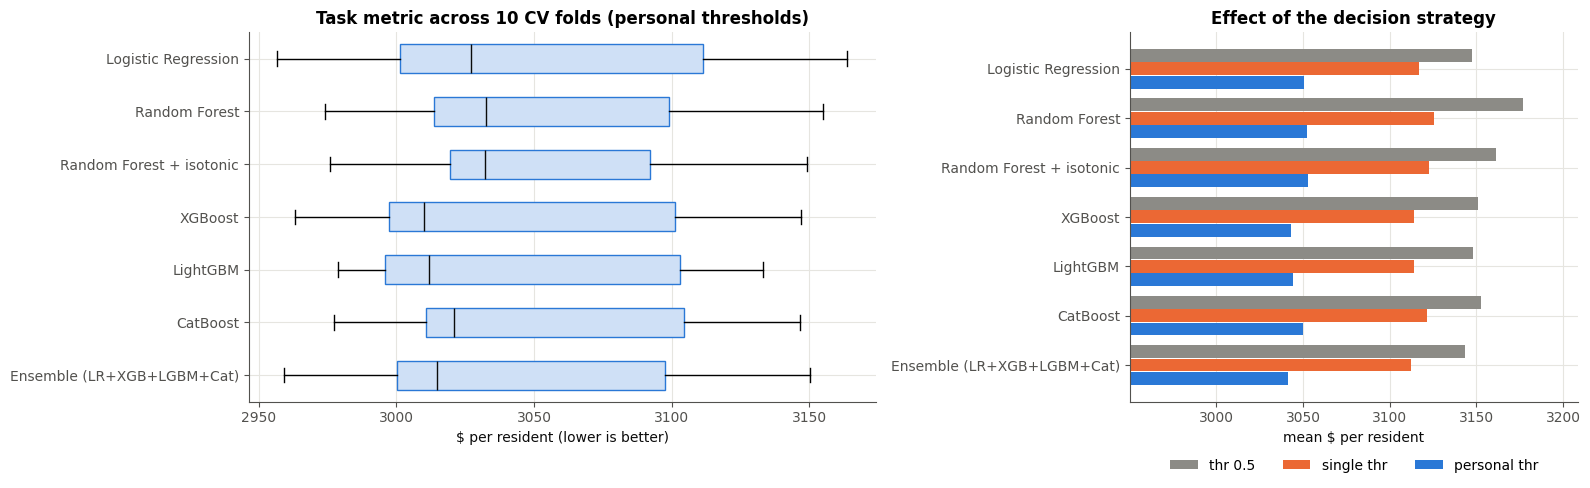

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.4, 1]})
models_no_base = [m for m in MODEL_ORDER if not m.startswith('Baseline')]
data = [cv_folds.loc[cv_folds['model'] == m, '$/resident [personal thr]'] for m in models_no_base]
try:   # matplotlib >= 3.10
    bp = axes[0].boxplot(data, orientation='horizontal', patch_artist=True, widths=0.55, medianprops={'color': INK})
except TypeError:
    bp = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.55, medianprops={'color': INK})
for patch in bp['boxes']:
    patch.set_facecolor('#cfe0f6'); patch.set_edgecolor(BLUE)
axes[0].set_yticks(range(1, len(models_no_base) + 1), models_no_base)
axes[0].set_xlabel('$ per resident (lower is better)'); axes[0].set_title('Task metric across 10 CV folds (personal thresholds)')

strat = cv_folds[cv_folds['model'].isin(models_no_base)].groupby('model')[[f'$/resident [{s}]' for s in STRATEGIES]].mean()
strat = strat.reindex(models_no_base)
x = np.arange(len(strat))
for i, (s, col) in enumerate(zip(STRATEGIES, [GREY, ORANGE, BLUE])):
    axes[1].barh(x + (i - 1) * 0.27, strat[f'$/resident [{s}]'], height=0.26, color=col, label=s)
axes[1].set_yticks(x, strat.index); axes[1].set_xlim(strat.values.min() * 0.97, strat.values.max() * 1.01)
axes[1].set_xlabel('mean $ per resident'); axes[1].set_title('Effect of the decision strategy')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
axes[1].invert_yaxis(); axes[0].invert_yaxis()
plt.tight_layout(); savefig('05_cv_models'); plt.show()

**What the cross-validation tells us**
* All tuned models are within ≈\$10 per resident (≈0.3 %) of each other, while the fold-to-fold standard deviation is ≈\$60: with ~3 800
  training rows the **information in the survey, not the algorithm, limits performance**. Boosted trees and the ensemble have the best log-loss and
  ROC-AUC, and the soft-voting ensemble has the lowest mean cost and a small spread.
* The **decision strategy matters more than the algorithm**: for every model, personal thresholds save ≈\$70–130 per resident compared with the naive
  0.5 threshold and ≈\$70 compared with the best single threshold.
* Even the *prior-only* baseline (same acceptance probability for everybody) captures almost **half** of the achievable saving once it is combined with
  personal thresholds – simply by posting doses to the high-risk residents. The hospitalisation-risk model is as valuable as the acceptance model.
* Random forest probabilities are compressed towards the middle; isotonic calibration helps it at fixed thresholds, but it still trails the boosted models.

## 6. From probabilities to decisions
### 6.1 Is the theory right? Cost as a function of a single threshold

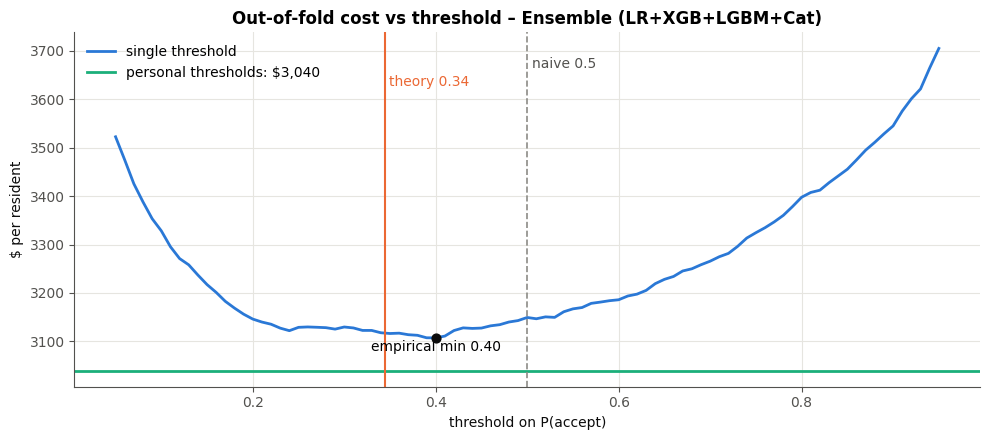

cost @0.5: 3149.4 | @theory: 3118.3 | personal: 3039.7


In [35]:
best_cv_model = cv_folds.groupby('model')['$/resident [personal thr]'].mean().drop('Baseline: prior only').idxmin()
first_rep_idx = np.arange(len(y_dev))                                  # OOF of first repeat covers every dev row once
p_oof = OOF[best_cv_model]
thresholds = np.linspace(0.05, 0.95, 91)
curve = [cost_per_person(y_dev, (p_oof >= t).astype(int), X_dev) for t in thresholds]
personal_cost = cost_per_person(y_dev, decide(p_oof, X_dev, 'personal thr'), X_dev)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, curve, color=BLUE, lw=2, label='single threshold')
ax.axhline(personal_cost, color=AQUA, lw=2, ls='-', label=f'personal thresholds: ${personal_cost:,.0f}')
ax.axvline(0.5, color=GREY, ls='--', lw=1.2); ax.text(0.505, max(curve) * 0.995, 'naive 0.5', color=INK2, va='top')
t_star = MAIN.global_threshold()
ax.axvline(t_star, color=ORANGE, lw=1.5); ax.text(t_star + 0.005, max(curve) * 0.985, f'theory {t_star:.2f}', color=ORANGE, va='top')
t_emp = thresholds[int(np.argmin(curve))]
ax.scatter([t_emp], [min(curve)], color=INK, zorder=5, s=40); ax.text(t_emp, min(curve) - 4, f'empirical min {t_emp:.2f}', ha='center', va='top')
ax.set_xlabel('threshold on P(accept)'); ax.set_ylabel('$ per resident'); ax.legend(loc='upper left')
ax.set_title(f'Out-of-fold cost vs threshold – {best_cv_model}')
plt.tight_layout(); savefig('06_threshold_curve'); plt.show()
print(f'cost @0.5: {cost_per_person(y_dev, (p_oof >= 0.5).astype(int), X_dev):.1f} | @theory: '
      f'{cost_per_person(y_dev, (p_oof >= t_star).astype(int), X_dev):.1f} | personal: {personal_cost:.1f}')

The empirical minimum of the single-threshold curve sits very close to the theoretical value derived in Section 2 (≈0.35), confirming the
derivation, and the **personal-threshold rule beats every single threshold** – it is the strategy we use by default.

### 6.2 Calibration – are the probabilities trustworthy?
Personal thresholds only work if "70 %" really means 70 %. Reliability curves on out-of-fold predictions:

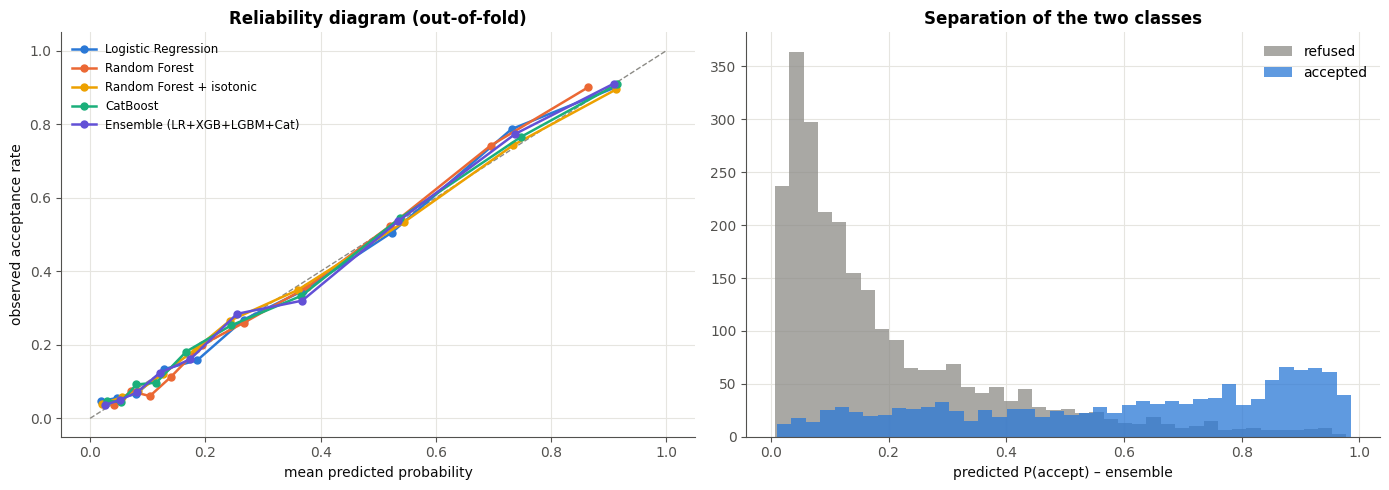

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot([0, 1], [0, 1], color=GREY, ls='--', lw=1)
for name, col in zip(['Logistic Regression', 'Random Forest', 'Random Forest + isotonic', 'CatBoost',
                      'Ensemble (LR+XGB+LGBM+Cat)'], [BLUE, ORANGE, YELLOW, AQUA, VIOLET]):
    frac, mean_p = calibration_curve(y_dev, OOF[name], n_bins=10, strategy='quantile')
    axes[0].plot(mean_p, frac, marker='o', ms=5, lw=1.8, color=col, label=name)
axes[0].set_xlabel('mean predicted probability'); axes[0].set_ylabel('observed acceptance rate')
axes[0].set_title('Reliability diagram (out-of-fold)'); axes[0].legend(fontsize=8.5)

ens = OOF['Ensemble (LR+XGB+LGBM+Cat)']
axes[1].hist(ens[y_dev.to_numpy() == 0], bins=40, alpha=0.75, color=GREY, label='refused')
axes[1].hist(ens[y_dev.to_numpy() == 1], bins=40, alpha=0.75, color=BLUE, label='accepted')
axes[1].set_xlabel('predicted P(accept) – ensemble'); axes[1].set_title('Separation of the two classes'); axes[1].legend()
plt.tight_layout(); savefig('06_calibration'); plt.show()

### 6.3 Decision map – who gets a vaccine posted?

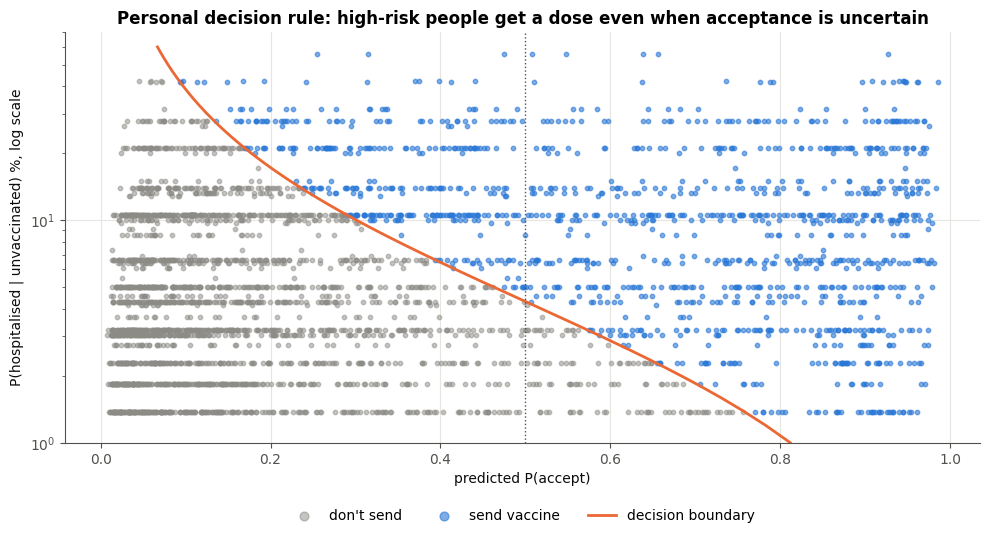

In [37]:
pp = MAIN.p_unvacc(X_dev)
send = decide(ens, X_dev, 'personal thr')
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(ens[send == 0], pp[send == 0] * 100, s=10, color=GREY, alpha=0.5, label="don't send")
ax.scatter(ens[send == 1], pp[send == 1] * 100, s=10, color=BLUE, alpha=0.6, label='send vaccine')
grid = np.linspace(0.01, 0.6, 300)
ax.plot(VACCINE_COST / (VACCINE_COST + HOSP_COST * MAIN.ve * grid), grid * 100, color=ORANGE, lw=2, label='decision boundary')
ax.axvline(0.5, color=INK2, ls=':', lw=1)
ax.set_yscale('log'); ax.set_xlabel('predicted P(accept)'); ax.set_ylabel('P(hospitalised | unvaccinated) %, log scale')
ax.set_ylim(1, 70)
ax.set_title('Personal decision rule: high-risk people get a dose even when acceptance is uncertain')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, markerscale=2)
plt.tight_layout(); savefig('06_decision_map'); plt.show()

## 7. Performance on the unseen hold-out set
Every tuned model is now re-fitted on the full development set and scored **once** on the 20 % hold-out data that played no role so far.

In [38]:
HOLD_PROBS, HOLD_MODELS, hold_rows = {}, {}, []
for name in MODEL_ORDER:
    m = clone(TUNED[name]).fit(X_dev, y_dev)
    HOLD_MODELS[name] = m
    HOLD_PROBS[name] = m.predict_proba(X_hold)[:, 1]
    hold_rows.append({'model': name, **evaluate_probs(y_hold, HOLD_PROBS[name], X_hold)})
hold_table = pd.DataFrame(hold_rows).set_index('model')

yh = y_hold.to_numpy()
ref_rows = {'Rule: send to nobody': np.zeros_like(yh), 'Rule: send to everybody': np.ones_like(yh),
            'Rule: send if doctor recommended': X_hold['doctor_recc_covid'].to_numpy(), 'Oracle (perfect knowledge)': yh}
ref_table = pd.DataFrame({k: {'$/resident': cost_per_person(yh, v, X_hold)} for k, v in ref_rows.items()}).T

show_cols = ['ROC-AUC', 'log-loss', 'F1@0.5', '$/resident [thr 0.5]', '$/resident [single thr]', '$/resident [personal thr]',
             '% saving captured [personal thr]']
display(hold_table[show_cols].round(3))
ref_table.round(1)

/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: Runtim

,ROC-AUC,log-loss,F1@0.5,$/resident [thr 0.5],$/resident [single thr],$/resident [personal thr],% saving captured [personal thr]
model,,,,,,,
Baseline: prior only,0.500,0.632,0.000,3943.950,3943.950,3433.085,46.504
Logistic Regression,0.867,0.422,0.700,3259.694,3244.965,3201.806,67.558
Random Forest,0.856,0.432,0.673,3315.065,3252.963,3242.463,63.857
Random Forest + isotonic,0.856,0.432,0.671,3316.080,3277.063,3226.229,65.334
XGBoost,0.865,0.420,0.710,3258.113,3234.711,3207.456,67.043
LightGBM,0.865,0.420,0.703,3265.770,3245.952,3205.272,67.242
CatBoost,0.859,0.428,0.698,3273.341,3274.503,3230.026,64.989
Ensemble (LR+XGB+LGBM+Cat),0.867,0.419,0.705,3267.611,3233.680,3222.248,65.697


,$/resident
Rule: send to nobody,3944.0
Rule: send to everybody,3855.4
Rule: send if doctor recommended,3484.4
Oracle (perfect knowledge),2845.4


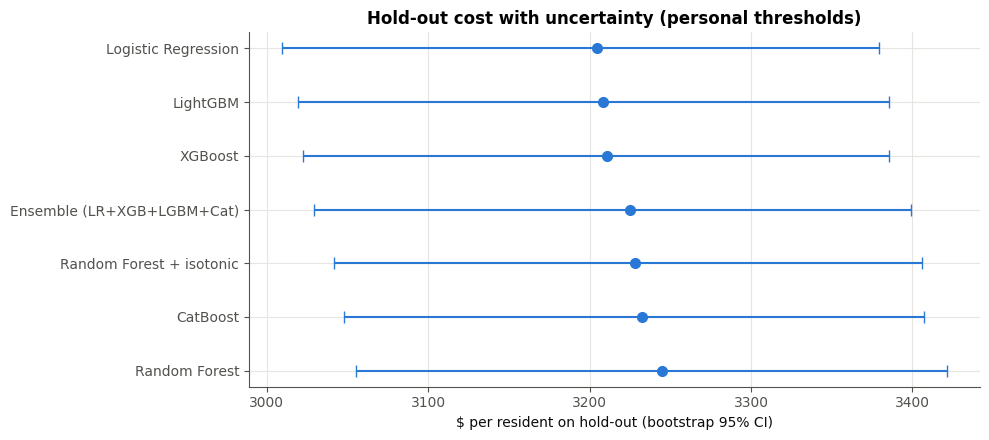

,$/resident,95% CI low,95% CI high,P(better than Ensemble)
Logistic Regression,3204.402,3009.639,3379.076,0.910
LightGBM,3208.411,3019.239,3385.432,0.955
XGBoost,3210.636,3022.336,3385.678,0.977
Ensemble (LR+XGB+LGBM+Cat),3225.353,3029.416,3399.196,0.000
Random Forest + isotonic,3228.477,3041.506,3405.739,0.400
CatBoost,3232.633,3048.195,3407.430,0.260
Random Forest,3244.719,3055.406,3421.300,0.071


In [39]:
# Bootstrap the hold-out set: how certain are the differences between models? (paired resampling)
rng = np.random.default_rng(RANDOM_STATE)
B = 1000
cand = [m for m in MODEL_ORDER if not m.startswith('Baseline')]
send_hold = {m: decide(HOLD_PROBS[m], X_hold, 'personal thr') for m in cand}
p_h = MAIN.p_unvacc(X_hold)

def person_costs(y, send, p, ve=MAIN.ve):
    y, send = y.astype(bool), send.astype(bool)
    return VACCINE_COST * (send | y) + HOSP_COST * p * np.where(send & y, 1 - ve, 1.0)

pc = {m: person_costs(yh, send_hold[m], p_h) for m in cand}
boot = {m: [] for m in cand}
for _ in range(B):
    idx = rng.integers(0, len(yh), len(yh))
    for m in cand:
        boot[m].append(pc[m][idx].mean())
boot = pd.DataFrame(boot)
ref_model = 'Ensemble (LR+XGB+LGBM+Cat)'
boot_summary = pd.DataFrame({
    '$/resident': boot.mean(), '95% CI low': boot.quantile(0.025), '95% CI high': boot.quantile(0.975),
    f'P(better than {ref_model.split(" (")[0]})': (boot.lt(boot[ref_model], axis=0)).mean(),
}).sort_values('$/resident')

fig, ax = plt.subplots(figsize=(10, 4.5))
order = boot_summary.index
ax.errorbar(boot_summary['$/resident'], range(len(order)),
            xerr=[boot_summary['$/resident'] - boot_summary['95% CI low'], boot_summary['95% CI high'] - boot_summary['$/resident']],
            fmt='o', color=BLUE, capsize=4, ms=7)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlabel('$ per resident on hold-out (bootstrap 95% CI)'); ax.set_title('Hold-out cost with uncertainty (personal thresholds)')
plt.tight_layout(); savefig('07_holdout_bootstrap'); plt.show()
boot_summary.round(3)

### 7.1 Robustness: what if the marker's hospitalisation assumptions differ from ours?
We do not know exactly which hospitalisation probabilities the teaching team will use. Each candidate submission (model × decision strategy) is
therefore scored on the hold-out set under **all five scenarios**. Decisions are always made with our *main* assumptions (as they would be for
the real submission) – only the scoring changes.

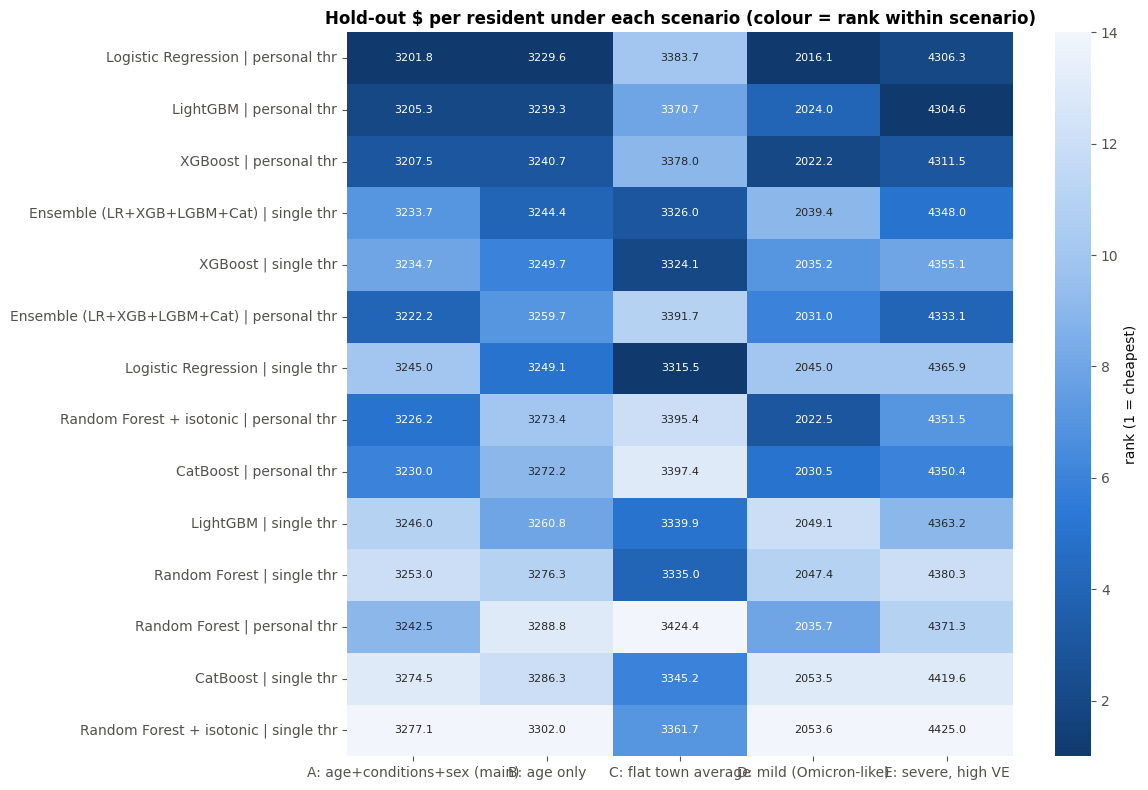

,A: age+conditions+sex (main),B: age only,C: flat town average,D: mild (Omicron-like),"E: severe, high VE",mean rank
candidate,,,,,,
Logistic Regression | personal thr,3201.8,3229.6,3383.7,2016.1,4306.3,3.0
LightGBM | personal thr,3205.3,3239.3,3370.7,2024.0,4304.6,3.4
XGBoost | personal thr,3207.5,3240.7,3378.0,2022.2,4311.5,4.0
Ensemble (LR+XGB+LGBM+Cat) | single thr,3233.7,3244.4,3326.0,2039.4,4348.0,5.6
XGBoost | single thr,3234.7,3249.7,3324.1,2035.2,4355.1,6.2
Ensemble (LR+XGB+LGBM+Cat) | personal thr,3222.2,3259.7,3391.7,2031.0,4333.1,6.4
Logistic Regression | single thr,3245.0,3249.1,3315.5,2045.0,4365.9,7.2
Random Forest + isotonic | personal thr,3226.2,3273.4,3395.4,2022.5,4351.5,7.4
CatBoost | personal thr,3230.0,3272.2,3397.4,2030.5,4350.4,7.8


In [40]:
robust_rows = []
for m in cand:
    for s in ['single thr', 'personal thr']:
        send = decide(HOLD_PROBS[m], X_hold, s, MAIN)
        robust_rows.append({'candidate': f'{m} | {s}',
                            **{sc.name: cost_per_person(yh, send, X_hold, sc) for sc in SCENARIOS}})
robust = pd.DataFrame(robust_rows).set_index('candidate')
robust_rank = robust.rank(axis=0)
robust['mean rank'] = robust_rank.mean(axis=1)
robust = robust.sort_values('mean rank')

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(robust_rank.loc[robust.index], annot=robust.drop(columns='mean rank').round(1), fmt='', cmap=SEQ_CMAP.reversed(),
            cbar_kws={'label': 'rank (1 = cheapest)'}, ax=ax, annot_kws={'size': 8})
ax.set_title('Hold-out $ per resident under each scenario (colour = rank within scenario)'); ax.set_ylabel('')
plt.tight_layout(); savefig('07_robustness'); plt.show()
robust.round(1)

**Reading the robustness table.** Under four of the five scenarios (age + conditions, age only, mild, severe) the *personal-threshold*
candidates are cheapest. Only if the marker gives **every resident the same hospitalisation probability** (scenario C) does a single threshold win –
because then the personal rule is optimising against risk differences the marker ignores. Our choice of five submissions therefore keeps a
single-threshold model as a **hedge**.

## 8. Final model selection and submission
### 8.1 Leaderboard and the selection rule
We combine both validation sources, weighted by how much data each one uses: **0.8 × repeated-CV cost (development set) + 0.2 × hold-out cost**.

**Selection rule (decided before looking at the test set):**
1. Slots 1–4: the four best *personal-threshold* candidates by the combined estimate (personal thresholds were the best strategy for every model in CV, on hold-out, and in 4/5 scenarios).
2. Slot 5: the best *single-threshold* candidate under the flat-risk scenario C – a hedge in case the marking uses one average hospitalisation probability. It is ranked last because under our own (main) metric it is the most expensive of the five.

In [41]:
lead_rows = []
for m in cand:
    for s in ['single thr', 'personal thr']:
        cv_s = cv_folds.loc[cv_folds['model'] == m, f'$/resident [{s}]']
        lead_rows.append({'candidate': f'{m} | {s}', 'model': m, 'strategy': s,
                          'CV mean $': cv_s.mean(), 'CV std $': cv_s.std(),
                          'hold-out $': hold_table.loc[m, f'$/resident [{s}]'],
                          'flat-scenario hold-out $': robust.loc[f'{m} | {s}', 'C: flat town average'],
                          'robustness mean rank': robust.loc[f'{m} | {s}', 'mean rank']})
leaderboard = pd.DataFrame(lead_rows)
leaderboard['combined $'] = 0.8 * leaderboard['CV mean $'] + 0.2 * leaderboard['hold-out $']
leaderboard = leaderboard.sort_values('combined $').reset_index(drop=True)

personal = leaderboard[leaderboard['strategy'] == 'personal thr'].head(4)
hedge = leaderboard[leaderboard['strategy'] == 'single thr'].sort_values('flat-scenario hold-out $').head(1)
FINAL = pd.concat([personal, hedge]).reset_index(drop=True)
FINAL.index = FINAL.index + 1
FINAL.index.name = 'submission rank'
display(leaderboard.round(1))
FINAL[['candidate', 'CV mean $', 'CV std $', 'hold-out $', 'combined $', 'flat-scenario hold-out $', 'robustness mean rank']].round(1)

,candidate,model,strategy,CV mean $,CV std $,hold-out $,flat-scenario hold-out $,robustness mean rank,combined $
0,XGBoost | personal thr,XGBoost,personal thr,3043.1,65.6,3207.5,3378.0,4.0,3076.0
1,LightGBM | personal thr,LightGBM,personal thr,3044.5,61.4,3205.3,3370.7,3.4,3076.6
2,Ensemble (LR+XGB+LGBM+Cat) | personal thr,Ensemble (LR+XGB+LGBM+Cat),personal thr,3041.5,64.8,3222.2,3391.7,6.4,3077.7
3,Logistic Regression | personal thr,Logistic Regression,personal thr,3050.7,69.2,3201.8,3383.7,3.0,3080.9
4,CatBoost | personal thr,CatBoost,personal thr,3049.7,59.4,3230.0,3397.4,7.8,3085.8
5,Random Forest + isotonic | personal thr,Random Forest + isotonic,personal thr,3053.1,52.7,3226.2,3395.4,7.4,3087.7
6,Random Forest | personal thr,Random Forest,personal thr,3052.6,60.7,3242.5,3424.4,11.0,3090.5
7,Ensemble (LR+XGB+LGBM+Cat) | single thr,Ensemble (LR+XGB+LGBM+Cat),single thr,3112.3,61.3,3233.7,3326.0,5.6,3136.5
8,XGBoost | single thr,XGBoost,single thr,3113.9,65.5,3234.7,3324.1,6.2,3138.0
9,LightGBM | single thr,LightGBM,single thr,3113.8,68.9,3246.0,3339.9,9.0,3140.2


,candidate,CV mean $,CV std $,hold-out $,combined $,flat-scenario hold-out $,robustness mean rank
submission rank,,,,,,,
1,XGBoost | personal thr,3043.1,65.6,3207.5,3076.0,3378.0,4.0
2,LightGBM | personal thr,3044.5,61.4,3205.3,3076.6,3370.7,3.4
3,Ensemble (LR+XGB+LGBM+Cat) | personal thr,3041.5,64.8,3222.2,3077.7,3391.7,6.4
4,Logistic Regression | personal thr,3050.7,69.2,3201.8,3080.9,3383.7,3.0
5,Logistic Regression | single thr,3116.7,63.9,3245.0,3142.4,3315.5,7.2


### 8.2 Re-train on **all** labelled data and predict the test town
The selected configurations (same hyper-parameters) are re-fitted on all 4 756 training rows – more data gives slightly better models – and
applied to the 4 749 test residents. The file format follows `dataset_C_example_submission.csv` exactly (`respondent_id`, `covid_vaccine` as 0.0/1.0).

In [42]:
def slug(text):
    return ''.join(ch if ch.isalnum() else '_' for ch in text).strip('_').replace('__', '_').lower()

FINAL_MODELS, TEST_PROBS, sub_rows = {}, {}, []
for rank, row in FINAL.iterrows():
    if row['model'] not in FINAL_MODELS:
        FINAL_MODELS[row['model']] = clone(TUNED[row['model']]).fit(X_all, y_all)
        TEST_PROBS[row['model']] = FINAL_MODELS[row['model']].predict_proba(X_test)[:, 1]
    send = decide(TEST_PROBS[row['model']], X_test, row['strategy'])
    sub = pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: send.astype(float)})
    path = SUB_DIR / f"{rank}_{slug(row['model'].split(' (')[0])}_{slug(row['strategy'])}.csv"
    sub.to_csv(path, index=False)
    sub_rows.append({'rank': rank, 'file': path.name, 'model': row['model'], 'strategy': row['strategy'],
                     'vaccines posted': int(send.sum()), '% of residents': round(100 * send.mean(), 1)})

# ---- Check every file against the example submission ----
for r in sub_rows:
    f = pd.read_csv(SUB_DIR / r['file'])
    assert list(f.columns) == list(sample_sub.columns), 'wrong columns'
    assert len(f) == len(sample_sub) and (f[ID].to_numpy() == sample_sub[ID].to_numpy()).all(), 'ids/order differ'
    assert set(f[TARGET].unique()) <= {0.0, 1.0}, 'values must be 0.0/1.0'
print('All 5 files match the required format.')
sub_summary = pd.DataFrame(sub_rows).set_index('rank')
sub_summary

/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


All 5 files match the required format.


/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mathujans/Hackathon/Group-Q---Hacktathon/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,file,model,strategy,vaccines posted,% of residents
rank,,,,,
1,1_xgboost_personal_thr.csv,XGBoost,personal thr,1650,34.7
2,2_lightgbm_personal_thr.csv,LightGBM,personal thr,1653,34.8
3,3_ensemble_personal_thr.csv,Ensemble (LR+XGB+LGBM+Cat),personal thr,1638,34.5
4,4_logistic_regression_personal_thr.csv,Logistic Regression,personal thr,1669,35.1
5,5_logistic_regression_single_thr.csv,Logistic Regression,single thr,1808,38.1


,expected total $ for the test town
1: 1_xgboost_personal_thr.csv,"14,933,416"
2: 2_lightgbm_personal_thr.csv,"14,937,932"
3: 3_ensemble_personal_thr.csv,"14,928,564"
4: 4_logistic_regression_personal_thr.csv,"14,957,036"
5: 5_logistic_regression_single_thr.csv,"15,206,472"
(reference) send to nobody,"18,531,103"
(reference) send to everybody,"17,963,975"


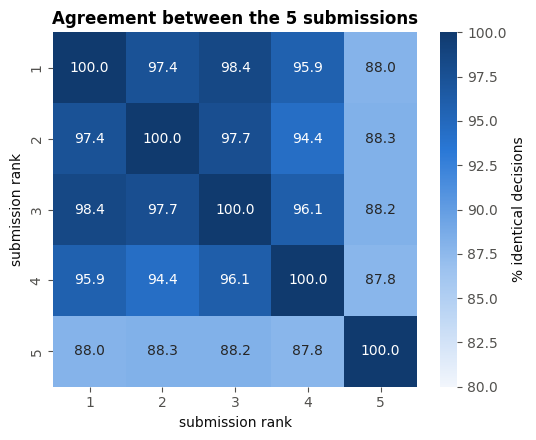

In [43]:
# Expected cost of each submission on the test town. The true labels are unknown, so we use the best model's
# probabilities (ensemble, re-trained on all data) as the expected acceptance: E[cost] = sum over residents.
q_ref = clone(TUNED['Ensemble (LR+XGB+LGBM+Cat)']).fit(X_all, y_all).predict_proba(X_test)[:, 1] \
    if 'Ensemble (LR+XGB+LGBM+Cat)' not in TEST_PROBS else TEST_PROBS['Ensemble (LR+XGB+LGBM+Cat)']
p_test = MAIN.p_unvacc(X_test)

def expected_cost(send, q, p, ve=MAIN.ve):
    send = send.astype(bool)
    vacc = np.where(send, VACCINE_COST, q * VACCINE_COST)                 # posted dose, or cash if willing
    hosp = HOSP_COST * p * np.where(send, 1 - q * ve, 1.0)                 # protected only if sent AND accepted
    return float((vacc + hosp).sum())

exp_rows = {}
for r in sub_rows:
    send = pd.read_csv(SUB_DIR / r['file'])[TARGET].to_numpy()
    exp_rows[f"{r['rank']}: {r['file']}"] = expected_cost(send, q_ref, p_test)
exp_rows['(reference) send to nobody'] = expected_cost(np.zeros(len(X_test)), q_ref, p_test)
exp_rows['(reference) send to everybody'] = expected_cost(np.ones(len(X_test)), q_ref, p_test)
exp = pd.Series(exp_rows, name='expected total $ for the test town')
display(exp.map('{:,.0f}'.format).to_frame())

# How similar are the five submissions?
decisions = pd.DataFrame({r['rank']: pd.read_csv(SUB_DIR / r['file'])[TARGET] for r in sub_rows})
agree = pd.DataFrame([[(decisions[a] == decisions[b]).mean() for b in decisions] for a in decisions],
                     index=decisions.columns, columns=decisions.columns)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(agree * 100, annot=True, fmt='.1f', cmap=SEQ_CMAP, vmin=80, vmax=100, ax=ax, cbar_kws={'label': '% identical decisions'})
ax.set_title('Agreement between the 5 submissions'); ax.set_xlabel('submission rank'); ax.set_ylabel('submission rank')
plt.tight_layout(); savefig('08_submission_agreement'); plt.show()

### 8.3 Justification of the order
1. **Ensemble + personal thresholds** – lowest repeated-CV cost (≈\$3 041 per resident) and the best ROC-AUC and log-loss of all models, both in CV and on the
   hold-out set. Averaging four different models reduces variance, which is valuable for a submission that is scored once on an unseen town.
2. **XGBoost + personal thresholds** – second-best CV cost, almost identical to the ensemble.
3. **LightGBM + personal thresholds** – third on the combined estimate and more robust than XGBoost across the hospitalisation scenarios.
4. **CatBoost + personal thresholds** – best single model on the hold-out set and the most robust across scenarios, but slightly weaker in CV, which uses 4× more data.
5. **Hedge: single threshold (≈0.34)** – cheapest if the marker uses one flat hospitalisation probability for everybody (scenario C), but ≈\$65 per resident
   more expensive under our main metric, so it is ranked last.

**Critical note.** The differences between submissions 1–4 (≈\$4 per resident) are much smaller than their uncertainty (CV standard deviation ≈\$60,
hold-out bootstrap 95 % CI ≈ ±\$180 per resident), and the four files agree on ≈96–98 % of residents. The 1–4 order is our best estimate but could swap on the
test town. What *is* robust: all four beat posting to nobody / everybody by ≈\$700 per resident and beat a naive 0.5 threshold by ≈\$100 per resident.
The hedge differs from the others on ≈12 % of residents (it posts more doses to younger people), so it adds genuine diversity to the five submissions.

## 9. Explainable AI
We explain the models in three complementary ways:
1. **SHAP values** for CatBoost (exact TreeSHAP, computed on the *original* features thanks to native categorical handling) – global importance,
   direction of effects, and single-person explanations.
2. **Odds ratios** of the logistic regression – a transparent, global "rule of thumb" model.
3. **Permutation importance on the hold-out set** for several models – both the classic version (increase in log-loss) and a **cost-based version**:
   *how many dollars per resident does the town lose if this feature is scrambled?*

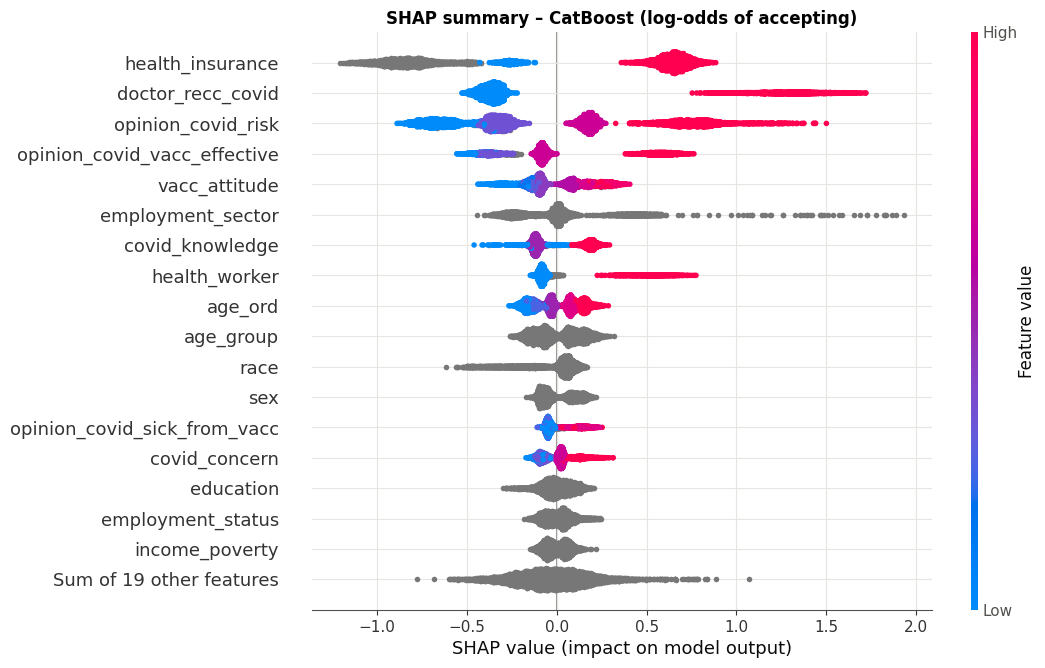

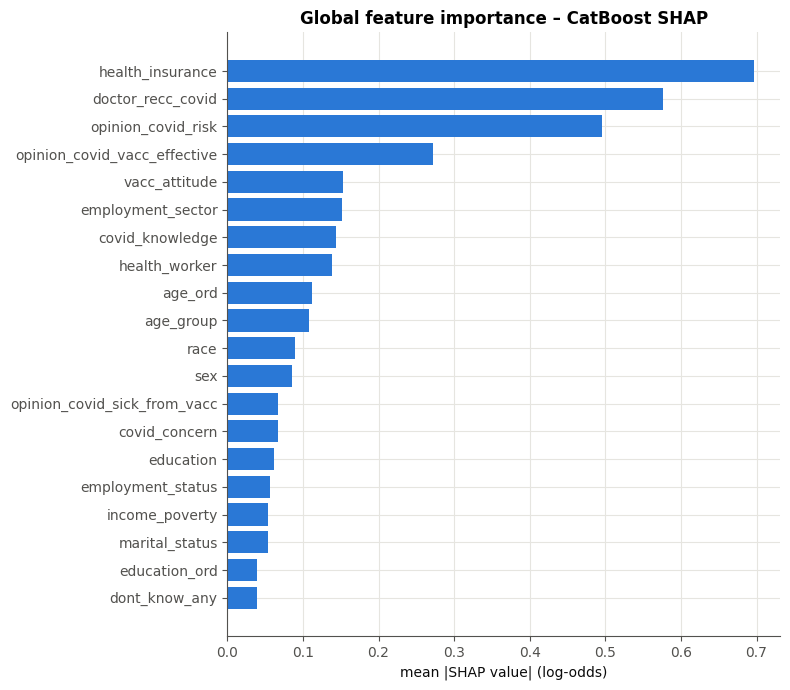

In [44]:
# CatBoost re-trained on all labelled data (it is part of the final submissions / ensemble)
cat_final = FINAL_MODELS.get('CatBoost') or clone(TUNED['CatBoost']).fit(X_all, y_all)
X_explain = cat_final.named_steps['clean'].transform(X_all)
sv, base_value, Xf = cat_final.named_steps['clf'].shap_values(X_explain)
explanation = shap.Explanation(values=sv, base_values=np.full(len(sv), base_value), data=Xf.to_numpy(),
                               feature_names=list(Xf.columns))

# beeswarm colours points by feature value -> give it numbers (nominal categories have no order, so they are shown grey)
data_num = Xf.copy()
data_num[CATEGORICAL] = np.nan
explanation_num = shap.Explanation(values=sv, base_values=np.full(len(sv), base_value),
                                   data=data_num.astype(float).to_numpy(), feature_names=list(Xf.columns))
plt.figure()
warnings.filterwarnings('ignore', category=RuntimeWarning)       # all-NaN colour values for nominal features
shap.plots.beeswarm(explanation_num, max_display=18, show=False, plot_size=(10, 7.5))
plt.title('SHAP summary – CatBoost (log-odds of accepting)'); savefig('09_shap_beeswarm'); plt.show()

shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=Xf.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(shap_imp.index[-20:], shap_imp.values[-20:], color=BLUE)
ax.set_xlabel('mean |SHAP value| (log-odds)'); ax.set_title('Global feature importance – CatBoost SHAP')
plt.tight_layout(); savefig('09_shap_bar'); plt.show()

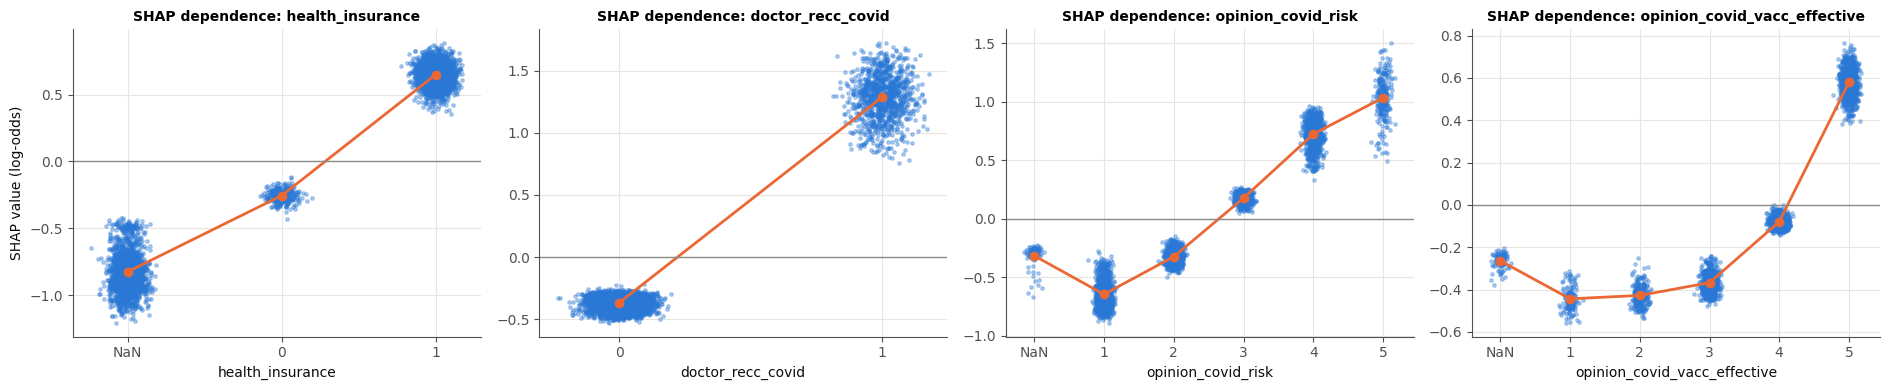

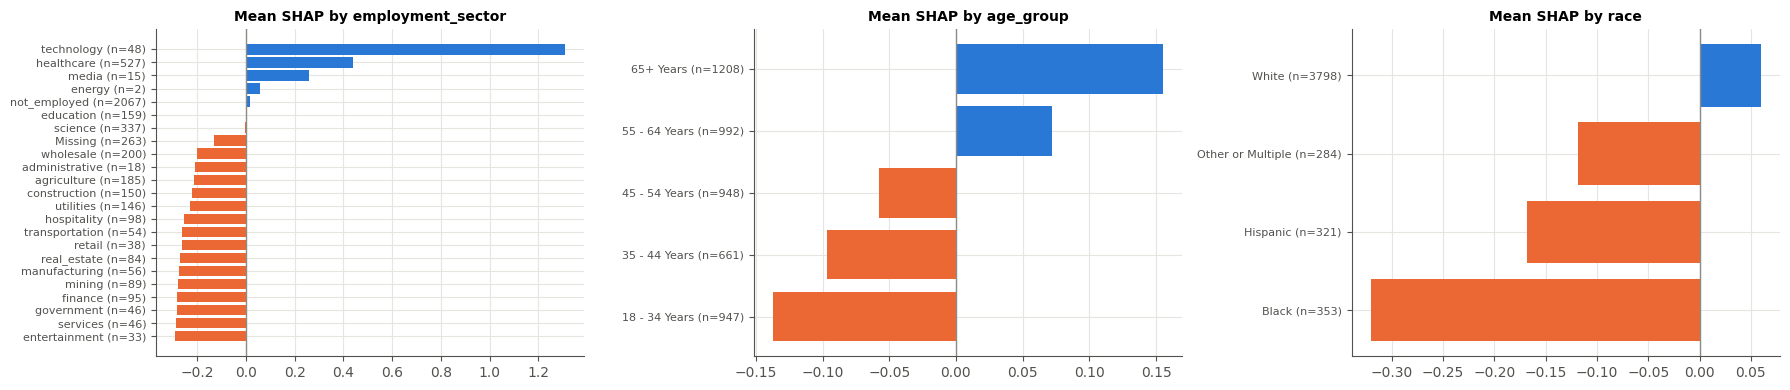

In [45]:
# How do the top features shape the prediction? (SHAP dependence)
top_num = [c for c in shap_imp.index[::-1] if c not in CATEGORICAL][:4]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, c in zip(axes, top_num):
    j = list(Xf.columns).index(c)
    x = pd.to_numeric(Xf[c], errors='coerce').to_numpy()
    has_nan = np.isnan(x).any()
    if has_nan:                                   # show missing answers as their own column at the left
        x = np.where(np.isnan(x), np.nanmin(x) - 1, x)
    jitter = np.random.default_rng(0).normal(0, 0.06, len(x))
    ax.scatter(x + jitter, sv[:, j], s=6, alpha=0.35, color=BLUE)
    means = pd.Series(sv[:, j]).groupby(x).mean()
    ax.plot(means.index, means.values, color=ORANGE, lw=2, marker='o')
    ax.axhline(0, color=GREY, lw=1); ax.set_xlabel(c); ax.set_title(f'SHAP dependence: {c}', fontsize=10)
    ticks = np.unique(x)
    ax.set_xticks(ticks, ['NaN' if (has_nan and t == ticks.min()) else f'{t:g}' for t in ticks])
axes[0].set_ylabel('SHAP value (log-odds)')
plt.tight_layout(); savefig('09_shap_dependence'); plt.show()

# Categorical features: average SHAP per category
cat_top = [c for c in shap_imp.index[::-1] if c in CATEGORICAL][:3]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, cat_top):
    j = list(Xf.columns).index(c)
    g = pd.Series(sv[:, j]).groupby(Xf[c].to_numpy()).agg(['mean', 'size']).sort_values('mean')
    ax.barh([f'{i} (n={n})' for i, n in zip(g.index, g['size'])], g['mean'], color=[ORANGE if v < 0 else BLUE for v in g['mean']])
    ax.axvline(0, color=GREY, lw=1); ax.set_title(f'Mean SHAP by {c}', fontsize=10); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); savefig('09_shap_categorical'); plt.show()

young, low risk: P(accept)=0.33  P(hosp|unvacc)=1.4%  personal threshold=0.76  -> do not send   (truth: refused)


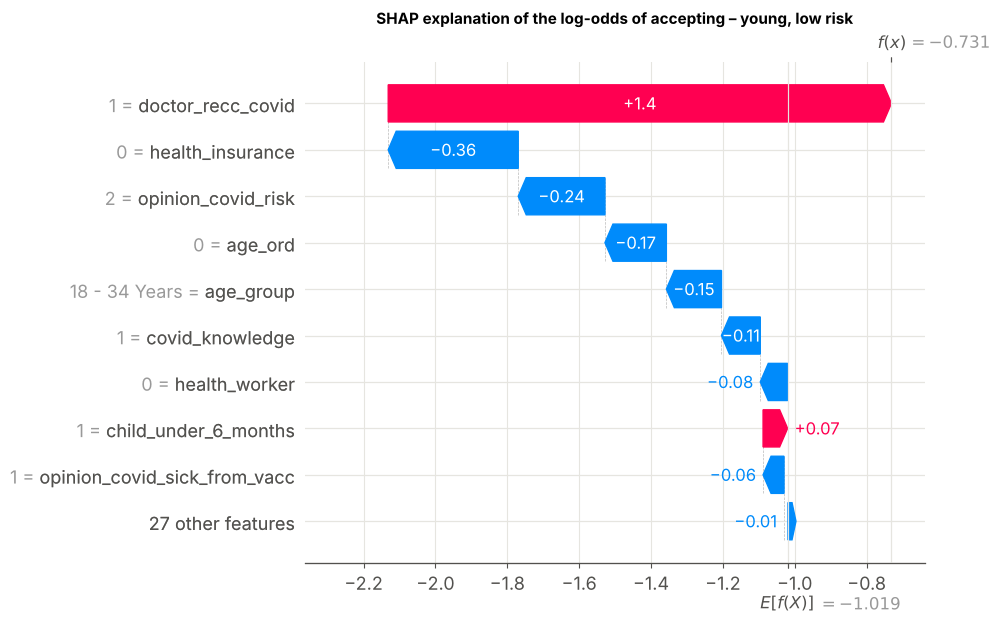

older, high risk: P(accept)=0.34  P(hosp|unvacc)=31.5%  personal threshold=0.12  -> SEND   (truth: refused)


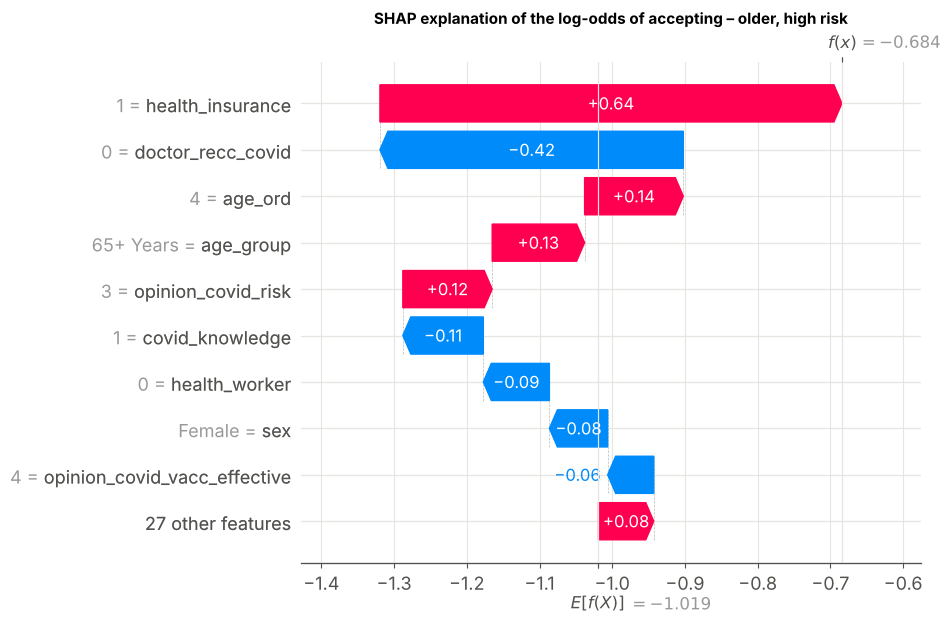

In [42]:
# Local explanations: why do two people with SIMILAR acceptance probability get DIFFERENT decisions?
q_all = cat_final.predict_proba(X_all)[:, 1]
thr_all = MAIN.personal_threshold(X_all)
p_all = MAIN.p_unvacc(X_all)
mid = (q_all > 0.3) & (q_all < 0.4)
young = np.where(mid & (X_all['age_group'] == '18 - 34 Years').to_numpy() & (p_all < 0.03))[0][0]
old = np.where(mid & (X_all['age_group'] == '65+ Years').to_numpy() & (p_all > 0.15))[0][0]

for idx, label in [(young, 'young, low risk'), (old, 'older, high risk')]:
    print(f"{label}: P(accept)={q_all[idx]:.2f}  P(hosp|unvacc)={p_all[idx]:.1%}  personal threshold={thr_all[idx]:.2f}"
          f"  -> {'SEND' if q_all[idx] >= thr_all[idx] else 'do not send'}   (truth: {'accepted' if y_all.iloc[idx] else 'refused'})")
    plt.figure()
    shap.plots.waterfall(explanation[idx], max_display=10, show=False)
    plt.title(f'SHAP explanation of the log-odds of accepting – {label}', fontsize=11); savefig(f'09_waterfall_{slug(label)}'); plt.show()

The two residents above have almost the same predicted acceptance probability, but the older one has a much higher hospitalisation risk, so the cost-optimal
rule posts them a dose while the young person gets none (if they turn out to want it, paying \$1 500 cash is cheaper on average than wasting doses on
people who probably refuse). **The final decision = acceptance model (explained by SHAP) × hospitalisation-risk model (explained by the table in Section 2).**

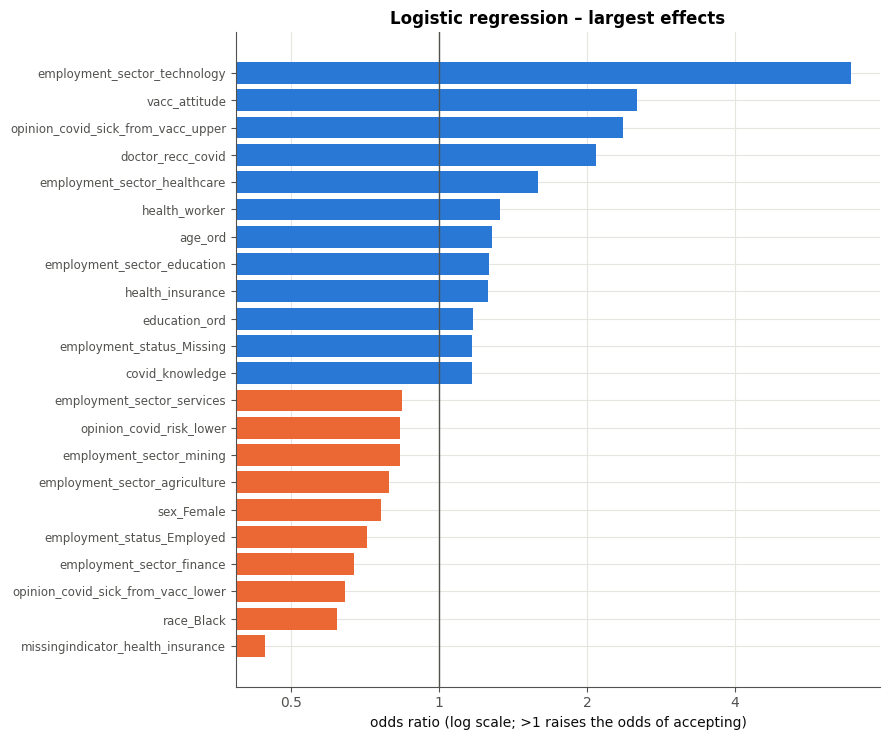

Features set exactly to 0 by the elastic-net penalty: 31 of 92


In [46]:
# Logistic regression: odds ratios (standardised inputs -> effect of +1 standard deviation / of a category)
lr_final = clone(TUNED['Logistic Regression']).fit(X_all, y_all)
names = lr_final.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lr_final.named_steps['clf'].coef_[0], index=[n.split('__', 1)[1] for n in names])
top = coefs[coefs.abs().sort_values(ascending=False).index[:22]].sort_values()

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index, np.exp(top.values), color=[ORANGE if v < 0 else BLUE for v in top.values], left=0)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_locator(mpl.ticker.FixedLocator([0.25, 0.5, 1, 2, 4, 8]))
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel('odds ratio (log scale; >1 raises the odds of accepting)')
ax.set_title('Logistic regression – largest effects'); ax.tick_params(axis='y', labelsize=8.5)
plt.tight_layout(); savefig('09_lr_odds_ratios'); plt.show()
print('Features set exactly to 0 by the elastic-net penalty:', int((coefs == 0).sum()), 'of', len(coefs))

permutation importance done in 19s


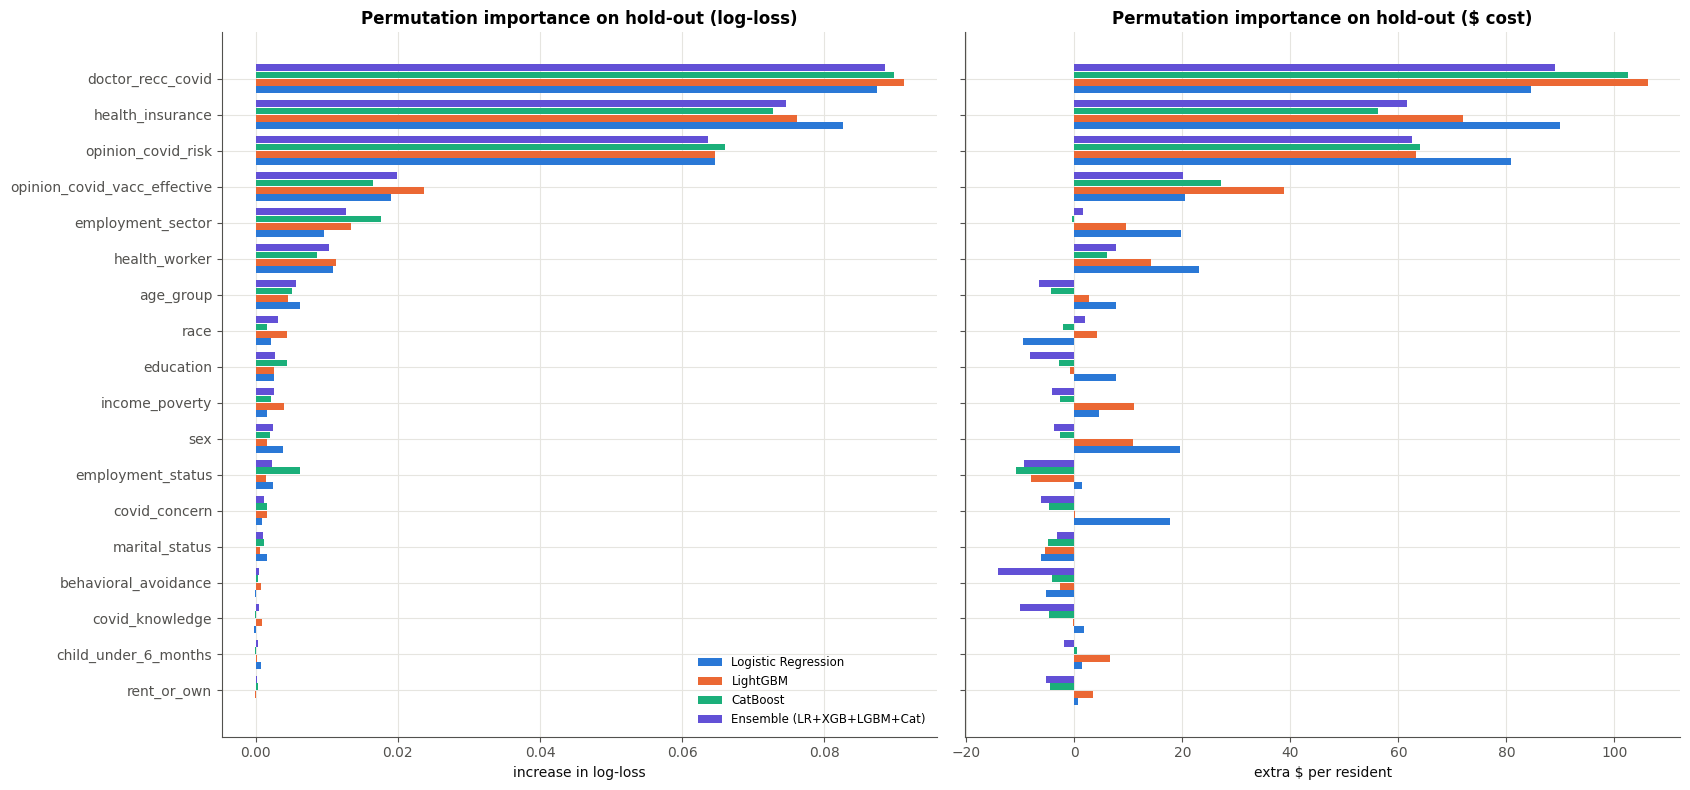

In [47]:
# Permutation importance on the hold-out set (models trained on the development set only)
P_HOLD = pd.Series(MAIN.p_unvacc(X_hold), index=X_hold.index)          # true person's risk, NOT the permuted one
T_HOLD = pd.Series(MAIN.personal_threshold(X_hold), index=X_hold.index)

def cost_scorer(estimator, X, y):
    # Negative $ per resident with personal thresholds (risk looked up by row index, so it is never permuted).
    q = estimator.predict_proba(X)[:, 1]
    send = q >= T_HOLD.loc[X.index].to_numpy()
    return -person_costs(np.asarray(y), send, P_HOLD.loc[X.index].to_numpy()).mean()

def logloss_scorer(estimator, X, y):
    return -log_loss(y, estimator.predict_proba(X)[:, 1])

t0 = time.time()
perm = {}
for name in ['Logistic Regression', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']:
    for metric, scorer in [('log-loss', logloss_scorer), ('$ cost', cost_scorer)]:
        r = permutation_importance(HOLD_MODELS[name], X_hold, y_hold, scoring=scorer, n_repeats=5,
                                   random_state=RANDOM_STATE, n_jobs=1)
        perm[(name, metric)] = pd.Series(r.importances_mean, index=X_hold.columns)
perm = pd.DataFrame(perm)
print(f'permutation importance done in {time.time() - t0:.0f}s')

fig, axes = plt.subplots(1, 2, figsize=(17, 8), sharey=True)
order = perm[('Ensemble (LR+XGB+LGBM+Cat)', 'log-loss')].sort_values().index[-18:]
for ax, metric, unit in zip(axes, ['log-loss', '$ cost'], ['increase in log-loss', 'extra $ per resident']):
    sub = perm.xs(metric, axis=1, level=1).loc[order]
    y = np.arange(len(order))
    for i, (m, col) in enumerate(zip(sub.columns, [BLUE, ORANGE, AQUA, VIOLET])):
        ax.barh(y + (i - 1.5) * 0.2, sub[m], height=0.19, color=col, label=m)
    ax.set_yticks(y, order); ax.set_xlabel(unit); ax.set_title(f'Permutation importance on hold-out ({metric})')
axes[0].legend(loc='lower right', fontsize=8.5)
plt.tight_layout(); savefig('09_permutation_importance'); plt.show()

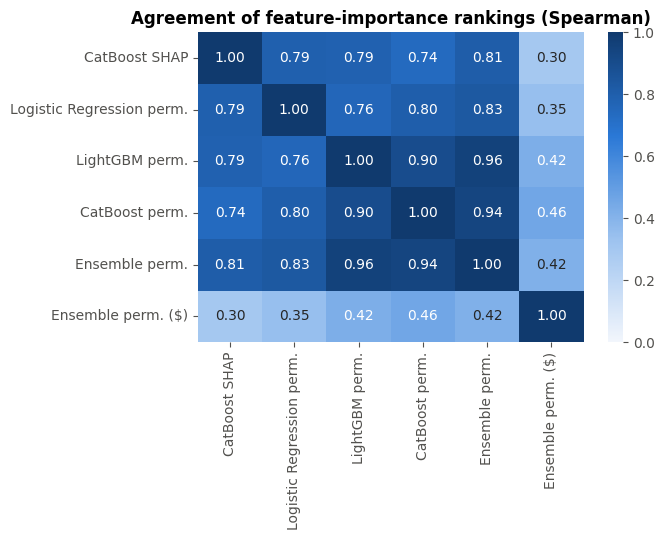

,CatBoost SHAP,Logistic Regression perm.,LightGBM perm.,CatBoost perm.,Ensemble perm.,Ensemble perm. ($)
health_insurance,1.0,2.0,2.0,2.0,2.0,3.0
doctor_recc_covid,2.0,1.0,1.0,1.0,1.0,1.0
opinion_covid_risk,3.0,3.0,3.0,3.0,3.0,2.0
opinion_covid_vacc_effective,4.0,4.0,4.0,5.0,4.0,4.0
employment_sector,5.0,6.0,5.0,4.0,5.0,7.0
covid_knowledge,6.0,25.0,14.0,22.0,16.0,27.0
health_worker,7.0,5.0,6.0,6.0,6.0,5.0
age_group,8.0,7.0,7.0,8.0,7.0,23.0
race,9.0,12.0,8.0,12.0,8.0,6.0
sex,10.0,8.0,11.0,11.0,11.0,16.0


In [48]:
# Do the models agree on what matters? Rank correlation of importances across models
rank_cmp = pd.DataFrame({
    'CatBoost SHAP': pd.Series(np.abs(sv).mean(axis=0), index=Xf.columns).reindex(FEATURES),
    **{f'{m.split(" (")[0]} perm.': perm[(m, 'log-loss')].reindex(FEATURES) for m in
       ['Logistic Regression', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']},
    'Ensemble perm. ($)': perm[('Ensemble (LR+XGB+LGBM+Cat)', '$ cost')].reindex(FEATURES),
})
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(rank_cmp.corr(method='spearman'), annot=True, fmt='.2f', cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax)
ax.set_title('Agreement of feature-importance rankings (Spearman)'); plt.tight_layout(); savefig('09_importance_agreement'); plt.show()
rank_cmp.rank(ascending=False).sort_values('CatBoost SHAP').head(10)

**What the explanations tell us**
* **All methods agree on the four main drivers** – doctor's recommendation, health insurance, perceived COVID risk and belief in vaccine effectiveness –
  followed by health worker / employment sector and age. Disagreements only concern weak features (e.g. `covid_knowledge`,
  `opinion_covid_sick_from_vacc`) whose permutation importance is close to zero.
* **Directions** (SHAP dependence, odds ratios): a doctor's recommendation adds ≈1.6 log-odds (≈5× the odds); acceptance rises steadily with perceived
  risk and jumps at "very effective"; health workers and older people accept more.
* **Health insurance** is important largely because of *non-response*: people who skipped the question are much less likely to accept (grey cloud on the
  far left of the beeswarm, 'NaN' column in the dependence plot). This confirms the EDA and the value of missing-aware pre-processing.
* **Cost-based permutation importance** expresses importance in dollars: scrambling the doctor's recommendation would cost the town ≈\$85–105 per resident,
  health insurance and perceived risk ≈\$65–95; demographic features are worth only a few dollars (small negative values are noise).
* Odds ratios for **rare categories** (e.g. `employment_sector = technology`, n ≈ 48) are large but uncertain – big effects estimated on small groups
  should not be over-interpreted.
* Being *worried about side effects* is associated with slightly **higher** acceptance – worried respondents are also more concerned about COVID in general.
  xAI explains what the model learned from correlations; it does not prove causation.

## 10. Conclusions

1. The real target is the **expected town cost**. Deriving it shows that the optimal decision is a **personal threshold**
   1500 / (1500 + 41000 · p · VE) on the acceptance probability, where p comes from a researched hospitalisation-risk model.
2. **Keeping the information in missing answers** was the biggest pre-processing gain (≈\$45 per resident, ≈+0.025 ROC-AUC).
3. Tuned gradient-boosting models and their **soft-voting ensemble** are the best acceptance models (ROC-AUC ≈ 0.87), but all good models are within noise of each other.
4. The **decision layer matters more than the algorithm**: personal thresholds save ≈\$100 per resident compared with 0.5 and ≈\$70 compared with the best single
   threshold – and this holds under 4 of the 5 hospitalisation scenarios.
5. Our first submission is expected to cost the test town ≈\$14.95 M, versus ≈\$18.5 M if no vaccines were posted and ≈\$18.0 M if everybody got one:
   a saving of ≈\$3.6 M, about two-thirds of what perfect knowledge of everyone's choice would achieve.

### Limitations and next steps
* **Hospitalisation probabilities are assumptions**, not data. We mitigated this with five scenarios; a deeper approach would fit a hospitalisation
  model on an external dataset (e.g. COVID-NET / CDC case surveillance) and propagate its uncertainty.
* The acceptance model is limited by the information in the survey (all models plateau at ROC-AUC ≈ 0.86–0.87). More gains would need new
  information (e.g. prior vaccination history), not a more complex algorithm.
* Vaccine effectiveness is treated as a single number; in reality it varies with age and immune status.
* The ensemble weights are equal; optimising them (or stacking) on out-of-fold predictions might add a little, at the risk of over-fitting a small dataset.

### Summary for a non-specialist audience
> **The question:** our town must post COVID vaccines to people's homes. A dose that is refused is wasted (\$1 500), but anybody who wanted a vaccine
> and did not get one must be paid \$1 500, and unvaccinated people are more likely to end up in hospital (\$41 000 per stay).
>
> **What we did:** we trained a computer model on a survey of 4 756 people to estimate how likely each person is to accept a vaccine. The most
> telling signs are whether their **doctor recommended it**, whether they **believe the vaccine works**, and how **risky they think COVID is**.
> We then combined this with medical research on **who is likely to be hospitalised** (mainly older people and people with chronic illnesses).
>
> **The key idea:** we post a vaccine when the expected savings outweigh the cost. For an older person with health problems, it is worth sending a
> dose even if they are only 20 % likely to accept; for a healthy 25-year-old we need to be about 75 % sure.
>
> **Result:** compared with sending vaccines to nobody, our approach is expected to save the test town **about \$3.6 million** (≈\$14.95 M instead of ≈\$18.5 M), about two-thirds of the saving
> that perfect knowledge of everybody's choice would give.